
# Incremental Value of Bioimpedance for Non-Imaging Gallstone Classification: A Leakage-Controlled Deployment-Tier Analysis With Validation-Strategy Sensitivity

**Dataset:** n = 319, 38 candidate predictors, binary outcome (gallstone disease present / absent). https://archive.ics.uci.edu/dataset/1150/gallstone-1

This notebook is a reliability audit and clinically constrained benchmark, not a search for the single best classifier. It is organized around four questions:

1. **Optimism**: does apparent discrimination survive leakage-safe, fully nested resampling, or is it inflated by validation strategies that let the same data inform both hyperparameter selection and performance reporting?
2. **Deployability**: how much predictive performance is retained by a Tier B model built only from routinely available clinical/anthropometric/laboratory data, relative to a Tier C model that adds bioimpedance-derived body-composition variables?
3. **Clinical usability**: is the predicted probability calibrated, and does a probability-based decision rule provide more net benefit than "refer everyone for further work-up" or "refer no one," across a plausible range of decision thresholds?
4. **Safe uncertainty**: can split-conformal prediction identify a subset of patients whose probability estimate is too ambiguous to act on, and route only that subset to confirmatory ultrasound rather than forcing a binary call on everyone?

**Primary research question:** Does adding bioimpedance-derived body-composition information (Tier C) improve gallstone classification beyond routinely available clinical and laboratory information (Tier B) — in a leakage-controlled sense, and is the improvement large enough to matter for a threshold-based decision rule?

**Secondary, methodological question:** How sensitive is the estimated Tier C − Tier B gain to the choice of validation strategy (single hold-out vs. ordinary/non-nested cross-validation vs. fully nested cross-validation)? This is not offered as a novel claim in isolation — leakage-safe nested CV on this exact dataset has been used before (e.g. Tandfonline 2026) — but here it is used as a methodological control for the primary question: any Tier C vs. Tier B claim is only as trustworthy as the validation strategy used to produce it, so we quantify how much that estimate would have moved under weaker validation.


## 1. Environment & configuration

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import os, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, GridSearchCV, train_test_split
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                              accuracy_score, roc_curve)
from sklearn.calibration import calibration_curve

import statsmodels.api as sm

sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


N_REPEATS_OPTIMISM   = 20
N_REPEATS_OOF        = 10
N_REPEATS_CONFORMAL  = 10
N_BOOT               = 2000

OUTER_CV = 5     # outer folds for nested CV and ordinary CV
INNER_CV = 3     # inner folds for hyperparameter tuning
ALPHA_CONFORMAL = 0.10   # miscoverage level -> target 90% marginal coverage

RESULTS_DIR = "results"
FIGURES_DIR = "figures"
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)


## 2. Data loading & integrity audit

Per the UCI codebook, Gallstone Status is coded 0 = gallstone present, 1 = gallstone absent. It is the
inverse of the usual "1 = positive" convention. We relabel to target = 1 for gallstone-present so that all
downstream AUCs, calibration curves, and decision curves refer to predicting disease presence, matching
how a clinician would read them.

In [ ]:
DATA_CSV  = "/content/sample_data/dataset-uci.csv"

df_raw = pd.read_csv(DATA_CSV)
print("Shape:", df_raw.shape)
df_raw.head()

Shape: (319, 39)


,Gallstone Status,Age,Gender,Comorbidity,Coronary Artery Disease (CAD),Hypothyroidism,Hyperlipidemia,Diabetes Mellitus (DM),Height,Weight,...,High Density Lipoprotein (HDL),Triglyceride,Aspartat Aminotransferaz (AST),Alanin Aminotransferaz (ALT),Alkaline Phosphatase (ALP),Creatinine,Glomerular Filtration Rate (GFR),C-Reactive Protein (CRP),Hemoglobin (HGB),Vitamin D
0,0,50,0,0,0,0,0,0,185,92.8,...,40.0,134.0,20.0,22.0,87.0,0.82,112.47,0.0,16.0,33.0
1,0,47,0,1,0,0,0,0,176,94.5,...,43.0,103.0,14.0,13.0,46.0,0.87,107.10,0.0,14.4,25.0
2,0,61,0,0,0,0,0,0,171,91.1,...,43.0,69.0,18.0,14.0,66.0,1.25,65.51,0.0,16.2,30.2
3,0,41,0,0,0,0,0,0,168,67.7,...,59.0,53.0,20.0,12.0,34.0,1.02,94.10,0.0,15.4,35.4
4,0,42,0,0,0,0,0,0,178,89.6,...,30.0,326.0,27.0,54.0,71.0,0.82,112.47,0.0,16.8,40.6


In [ ]:

TARGET_RAW = "Gallstone Status"

# integrity checks
audit = {}
audit["n_rows"] = len(df_raw)
audit["n_cols"] = df_raw.shape[1]
audit["n_missing_total"] = int(df_raw.isnull().sum().sum())
audit["n_duplicate_rows"] = int(df_raw.duplicated().sum())
audit["target_value_counts"] = df_raw[TARGET_RAW].value_counts().to_dict()

print(json.dumps(audit, indent=2, default=str))

assert audit["n_missing_total"] == 0, "Unexpected missing values — investigate before proceeding."
assert audit["n_duplicate_rows"] == 0, "Unexpected duplicate rows — investigate before proceeding."

# range / plausibility scan: flag (not silently fix) any implausible values
numeric_cols = df_raw.select_dtypes(include=[np.number]).columns.tolist()
range_table = df_raw[numeric_cols].agg(["min", "max", "mean", "std"]).T
range_table.columns = ["min", "max", "mean", "std"]
range_table["cv"] = range_table["std"] / range_table["mean"].abs()
suspicious = range_table.sort_values("cv", ascending=False).head(5)
print("\nColumns with the highest coefficient of variation (candidates for data-entry review):")
suspicious


{
  "n_rows": 319,
  "n_cols": 39,
  "n_missing_total": 0,
  "n_duplicate_rows": 0,
  "target_value_counts": {
    "0": 161,
    "1": 158
  }
}

Columns with the highest coefficient of variation (candidates for data-entry review):


,min,max,mean,std,cv
Hyperlipidemia,0.0,1.0,0.025078,0.156609,6.244778
Hypothyroidism,0.0,1.0,0.028213,0.165841,5.878160
Coronary Artery Disease (CAD),0.0,1.0,0.037618,0.190568,5.065944
Obesity (%),0.4,1954.0,35.850125,109.799718,3.062743
C-Reactive Protein (CRP),0.0,43.4,1.853856,4.989591,2.691467


Obesity (%) contains a single extreme outlier (max ~1954, vs. IQR ~14-42) almost certainly a data-entry artifact in the public release rather than a physiological value. We do not correct or remove it: it is retained in the analysis (so results are reproducible against the published dataset as-is), preprocessing uses RobustScaler (median/IQR) rather than StandardScaler specifically because of this.

In [ ]:
outlier_col = "Obesity (%)"
if outlier_col in df_raw.columns:
    print(df_raw[outlier_col].describe())
    print("\nTop 3 values:")
    print(df_raw[outlier_col].sort_values(ascending=False).head(3))

count     319.000000
mean       35.850125
std       109.799718
min         0.400000
25%        13.900000
50%        25.600000
75%        41.750000
max      1954.000000
Name: Obesity (%), dtype: float64

Top 3 values:
239    1954.0
23      125.6
209     106.3
Name: Obesity (%), dtype: float64


In [ ]:
# target relabeling: 1 = gallstone present
df = df_raw.copy()
df["target"] = 1 - df[TARGET_RAW]
df = df.drop(columns=[TARGET_RAW])

print("Relabeled target counts (1 = gallstone present):")
print(df["target"].value_counts())
print(f"Prevalence: {df['target'].mean():.3f}")

Relabeled target counts (1 = gallstone present):
target
1    161
0    158
Name: count, dtype: int64
Prevalence: 0.505



## 3. Feature-tier definition

The tiers are defined by acquisition modality, before any modeling, so that the question being asked is
"is the extra measurement modality worth it?" rather than "which variables does a selection algorithm
like?". This is the key methodological departure from prior work on this dataset, which mixes modalities
before feature selection.

- **Tier B — routine clinical/lab tier.** Anything obtainable from a scale, stadiometer, patient interview/chart,
  and a standard venous blood panel. No body-composition analyzer required.
- **Tier C — Tier B + bioimpedance tier.** Adds every variable the UCI documentation attributes to the
  bioelectrical impedance analysis (BIA) device output — including *Hepatic Fat Accumulation*, which the UCI
  variable description groups under "bioimpedance data" alongside water compartments, muscle/fat mass,
  protein, and visceral fat area.

The two lists partition the full 38-variable feature set exactly (verified programmatically below), so Tier C
is strictly Tier B plus the incremental modality. No variable is dropped or reassigned between tiers.


In [ ]:

TIER_B_FEATURES = [
    # Demographic / anthropometric (scale + stadiometer)
    "Age", "Gender", "Height", "Weight", "Body Mass Index (BMI)",
    # Clinical history (chart / interview)
    "Comorbidity", "Coronary Artery Disease (CAD)", "Hypothyroidism",
    "Hyperlipidemia", "Diabetes Mellitus (DM)",
    # Routine venous laboratory panel
    "Glucose", "Total Cholesterol (TC)", "Low Density Lipoprotein (LDL)",
    "High Density Lipoprotein (HDL)", "Triglyceride",
    "Aspartat Aminotransferaz (AST)", "Alanin Aminotransferaz (ALT)",
    "Alkaline Phosphatase (ALP)", "Creatinine", "Glomerular Filtration Rate (GFR)",
    "C-Reactive Protein (CRP)", "Hemoglobin (HGB)", "Vitamin D",
]

TIER_C_ADDITIONAL_FEATURES = [
    # Bioelectrical impedance analysis (BIA) device output only
    "Total Body Water (TBW)", "Extracellular Water (ECW)", "Intracellular Water (ICW)",
    "Extracellular Fluid/Total Body Water (ECF/TBW)", "Total Body Fat Ratio (TBFR) (%)",
    "Lean Mass (LM) (%)", "Body Protein Content (Protein) (%)", "Visceral Fat Rating (VFR)",
    "Bone Mass (BM)", "Muscle Mass (MM)", "Obesity (%)", "Total Fat Content (TFC)",
    "Visceral Fat Area (VFA)", "Visceral Muscle Area (VMA) (Kg)",
    "Hepatic Fat Accumulation (HFA)",
]

TIER_C_FEATURES = TIER_B_FEATURES + TIER_C_ADDITIONAL_FEATURES

all_feature_cols = [c for c in df.columns if c != "target"]
assert set(TIER_C_FEATURES) == set(all_feature_cols), "Tier mapping does not exactly cover all features!"
assert len(TIER_C_FEATURES) == len(all_feature_cols), "Tier mapping has duplicate or missing entries!"

tier_table = pd.DataFrame({
    "variable": all_feature_cols,
    "tier": ["B" if c in TIER_B_FEATURES else "C-additional" for c in all_feature_cols],
})
tier_table = tier_table.sort_values(["tier", "variable"]).reset_index(drop=True)
print(f"Tier B: {len(TIER_B_FEATURES)} features | Tier C additional: {len(TIER_C_ADDITIONAL_FEATURES)} "
      f"features | Tier C total: {len(TIER_C_FEATURES)} features")
tier_table.to_csv(f"{RESULTS_DIR}/table1_feature_tiers.csv", index=False)
tier_table


Tier B: 23 features | Tier C additional: 15 features | Tier C total: 38 features


,variable,tier
0,Age,B
1,Alanin Aminotransferaz (ALT),B
2,Alkaline Phosphatase (ALP),B
3,Aspartat Aminotransferaz (AST),B
4,Body Mass Index (BMI),B
5,C-Reactive Protein (CRP),B
6,Comorbidity,B
7,Coronary Artery Disease (CAD),B
8,Creatinine,B
9,Diabetes Mellitus (DM),B


## 4. Exploratory data analysis

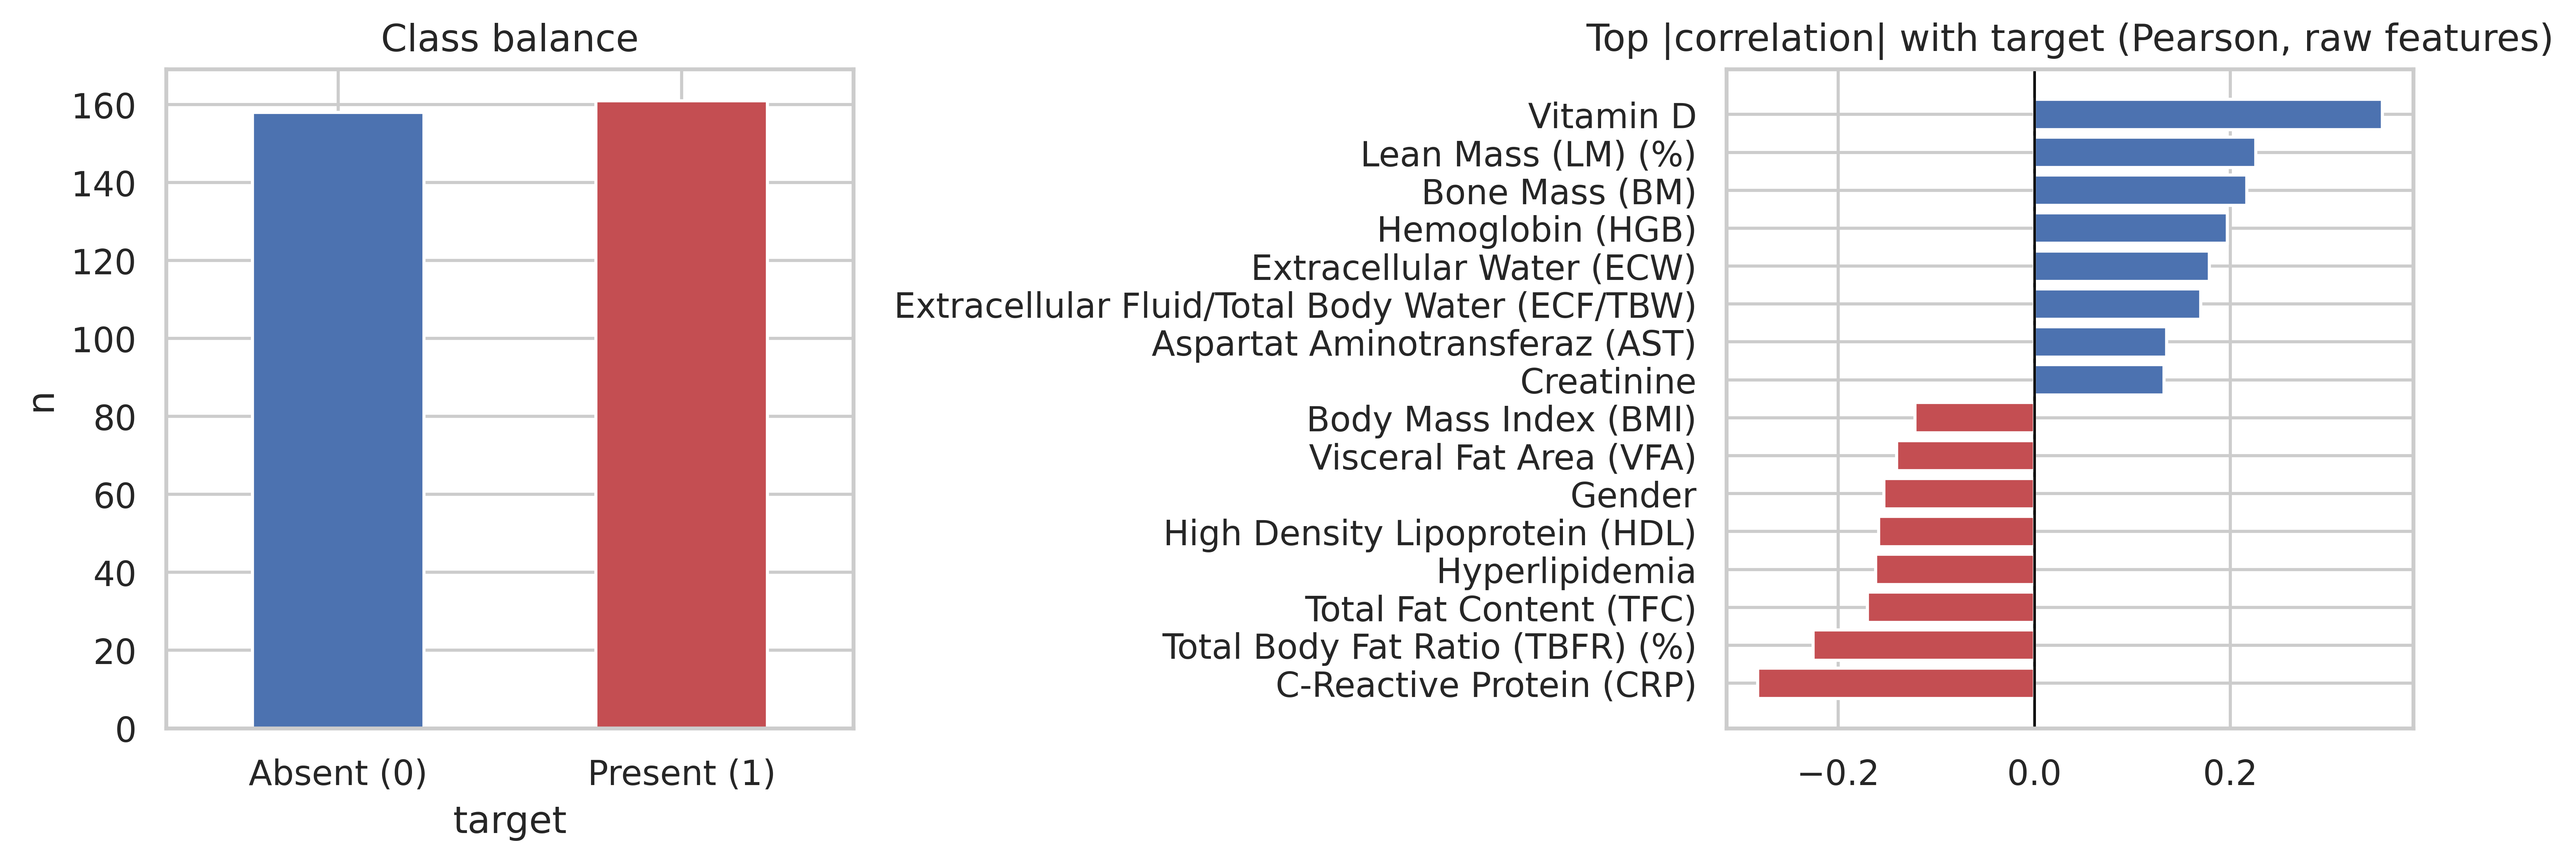

In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(11, 4),dpi=600)

df["target"].value_counts().sort_index().plot(
    kind="bar", ax=axes[0], color=["#4C72B0", "#C44E52"])
axes[0].set_xticklabels(["Absent (0)", "Present (1)"], rotation=0)
axes[0].set_title("Class balance")
axes[0].set_ylabel("n")

corr = df[all_feature_cols + ["target"]].corr(numeric_only=True)["target"].drop("target").sort_values()
top_corr = pd.concat([corr.head(8), corr.tail(8)])
colors = ["#C44E52" if v < 0 else "#4C72B0" for v in top_corr.values]
axes[1].barh(top_corr.index, top_corr.values, color=colors)
axes[1].set_title("Top |correlation| with target (Pearson, raw features)")
axes[1].axvline(0, color="black", linewidth=0.8)

plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/fig1_eda_overview.png", dpi=600, bbox_inches="tight")
plt.show()


## 5. Modeling pipeline: preprocessing, model zoo, hyperparameter grids

We deliberately use a small, well-characterized model zoo (4 model classes) rather than a large
leaderboard-style comparison. A reliability-audit paper benefits from a few models whose optimism and
calibration behavior can be examined in depth, not from a horse race across ten algorithms.

All 38 raw variables are already numerically encoded in the source file (binary/ordinal history and exam
variables as 0/1/2/3, continuous labs and BIA outputs as floats), so no categorical encoding step is needed.
Preprocessing is median imputation (safety net; the data has no missing values) + RobustScaler
(median/IQR is chosen over StandardScaler because of the documented Obesity (%) outlier in Section 2;
IQR-based scaling limits its leverage on distance- and gradient-based models without deleting a data point
from the published dataset).

In [ ]:
def make_preprocessor(feature_list):
    return ColumnTransformer([
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", RobustScaler()),
        ]), feature_list)
    ])

def make_model_zoo():
    # Model class + hyperparameter grid, held constant across tiers and
    # validation strategies (only the validation strategy and feature tier vary).
    return {
        "LogReg_EN": (
            LogisticRegression(solver="saga", max_iter=5000, random_state=RANDOM_STATE),
            {"model__C": [0.05, 0.2, 1, 5], "model__l1_ratio": [0.0, 0.5, 1.0], "model__penalty": ["elasticnet"]}
        ),
        "RandomForest": (
            RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
            {"model__n_estimators": [200], "model__max_depth": [None, 6], "model__min_samples_leaf": [2, 5]}
        ),
        "HistGB": (
            HistGradientBoostingClassifier(random_state=RANDOM_STATE),
            {"model__max_iter": [150], "model__learning_rate": [0.05, 0.1], "model__max_depth": [None, 3]}
        ),
        "SVM_RBF": (
            SVC(probability=True, random_state=RANDOM_STATE),
            {"model__C": [0.5, 2, 8], "model__gamma": ["scale", 0.02]}
        ),
    }

def get_estimator_for(name):
    return make_model_zoo()[name][0]

def get_grid_for(name):
    return make_model_zoo()[name][1]

def build_pipeline(feature_list, model):
    est = clone(model)
    return Pipeline([
        ("preprocessor", make_preprocessor(feature_list)),
        ("model", est),
    ])

MODEL_NAMES = ["LogReg_EN", "RandomForest", "HistGB", "SVM_RBF"]
TIERS = {"B": TIER_B_FEATURES, "C": TIER_C_FEATURES}

print("Model zoo:", MODEL_NAMES)
print("Hyperparameter grids are IDENTICAL across Tier B and Tier C runs of the same model class, "
      "and across all three validation strategies below, so any performance difference reflects the "
      "feature tier and/or validation strategy — not a moving target.")


Model zoo: ['LogReg_EN', 'RandomForest', 'HistGB', 'SVM_RBF']
Hyperparameter grids are IDENTICAL across Tier B and Tier C runs of the same model class, and across all three validation strategies below, so any performance difference reflects the feature tier and/or validation strategy — not a moving target.



## 6. Three validation strategies (shared implementation)

Same model class, same feature tier, same preprocessing, same hyperparameter grid — only the validation
architecture changes:

- **(a) Single stratified hold-out.** One 80/20 split. Hyperparameters tuned by 3-fold CV *on the training
  portion only*; the test portion is touched exactly once, at the end, for reporting. This is the strategy
  with the smallest effective test set and the highest run-to-run variance.
- **(b) Ordinary (non-nested) cross-validation.** The classic approach in which
  hyperparameters are selected using GridSearchCV over the same K folds whose held-out predictions are
  then reported as "the" cross-validated performance. This is the textbook source of optimism: the reported
  score and the model-selection score are the same number.
- **(c) Fully nested cross-validation.** An outer StratifiedKFold produces test folds that are never seen
  during hyperparameter search; an inner StratifiedKFold inside each outer-training fold handles tuning.
  Performance is the mean of the outer-fold test scores. This is the leakage-safe reference standard.

Each strategy is repeated over multiple random seeds (varying the fold/split assignment) to build a
distribution rather than a single point estimate.

In [ ]:

def _metrics_from_preds(y_true, p):
    return dict(
        auc=roc_auc_score(y_true, p),
        pr_auc=average_precision_score(y_true, p),
        brier=brier_score_loss(y_true, p),
        acc=accuracy_score(y_true, (p >= 0.5).astype(int)),
    )

def run_holdout(X, y, features, model_name, seed):
    est, grid = get_estimator_for(model_name), get_grid_for(model_name)
    pipe = build_pipeline(features, est)
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=seed, stratify=y)
    inner = StratifiedKFold(n_splits=INNER_CV, shuffle=True, random_state=seed)
    gs = GridSearchCV(pipe, grid, scoring="roc_auc", cv=inner, n_jobs=-1)
    gs.fit(Xtr, ytr)
    p = gs.predict_proba(Xte)[:, 1]
    return _metrics_from_preds(yte, p)

def run_ordinary_cv(X, y, features, model_name, seed):
    # Classic leakage-prone approach: the hyperparameters are selected using
    # the SAME cross-validation loop that is then reported as the performance
    # estimate.
    est, grid = get_estimator_for(model_name), get_grid_for(model_name)
    pipe = build_pipeline(features, est)
    cv = StratifiedKFold(n_splits=OUTER_CV, shuffle=True, random_state=seed)
    gs = GridSearchCV(pipe, grid, scoring="roc_auc", cv=cv, n_jobs=-1, refit=False)
    gs.fit(X, y)
    best_idx = gs.best_index_
    auc_selected = gs.cv_results_["mean_test_score"][best_idx]
    best_params = gs.cv_results_["params"][best_idx]
    # Re-run the same CV split with the selected hyperparameters to obtain
    # out-of-fold predictions for the other metrics (pr_auc/brier/acc),
    # consistent with how the AUC above was produced.
    pipe2 = clone(pipe).set_params(**best_params)
    oof = np.zeros(len(y))
    for tr_idx, te_idx in cv.split(X, y):
        pipe2.fit(X.iloc[tr_idx], y[tr_idx])
        oof[te_idx] = pipe2.predict_proba(X.iloc[te_idx])[:, 1]
    m = _metrics_from_preds(y, oof)
    m["auc"] = auc_selected  # the number ordinary CV would actually report
    return m

def run_nested_cv(X, y, features, model_name, seed, return_oof=False):
    est, grid = get_estimator_for(model_name), get_grid_for(model_name)
    outer = StratifiedKFold(n_splits=OUTER_CV, shuffle=True, random_state=seed)
    fold_metrics = []
    oof = np.full(len(y), np.nan)
    for tr_idx, te_idx in outer.split(X, y):
        Xtr, Xte = X.iloc[tr_idx], X.iloc[te_idx]
        ytr, yte = y[tr_idx], y[te_idx]
        pipe = build_pipeline(features, est)
        inner = StratifiedKFold(n_splits=INNER_CV, shuffle=True, random_state=seed)
        gs = GridSearchCV(pipe, grid, scoring="roc_auc", cv=inner, n_jobs=-1)
        gs.fit(Xtr, ytr)
        p = gs.predict_proba(Xte)[:, 1]
        oof[te_idx] = p
        fold_metrics.append(_metrics_from_preds(yte, p))
    agg = {k: np.mean([f[k] for f in fold_metrics]) for k in fold_metrics[0]}
    if return_oof:
        return agg, oof
    return agg

## 7. Experiment 1: Optimism quantification across validation strategies

For every combination of {4 model classes} × {2 tiers} × {3 validation strategies}, we repeat the estimate
N_REPEATS_OPTIMISM times with different fold/split seeds and record AUC, PR-AUC, Brier score, and accuracy.
Results are cached to results/experiment1_results.csv


In [ ]:
exp1_path = f"{RESULTS_DIR}/experiment1_results.csv"

if os.path.exists(exp1_path):
    exp1_results = pd.read_csv(exp1_path)
    print(f"Loaded cached results: {exp1_path} ({len(exp1_results)} rows)")
else:
    rows = []
    t0 = time.time()
    for seed in range(N_REPEATS_OPTIMISM):
        for tier_name, feats in TIERS.items():
            for mname in MODEL_NAMES:
                h = run_holdout(df[feats], df["target"].values, feats, mname, seed=seed)
                o = run_ordinary_cv(df[feats], df["target"].values, feats, mname, seed=seed)
                n = run_nested_cv(df[feats], df["target"].values, feats, mname, seed=seed)
                for strat, m in [("holdout", h), ("ordinary_cv", o), ("nested_cv", n)]:
                    rows.append(dict(seed=seed, tier=tier_name, model=mname, strategy=strat, **m))
        elapsed = time.time() - t0
        print(f"  seed {seed+1}/{N_REPEATS_OPTIMISM} done | elapsed {elapsed:.0f}s", flush=True)
        pd.DataFrame(rows).to_csv(exp1_path, index=False)  # checkpoint after every seed
    exp1_results = pd.DataFrame(rows)
    print(f"Experiment 1 complete in {time.time()-t0:.0f}s -> {exp1_path}")

exp1_results.head()

  seed 1/20 done | elapsed 220s
  seed 2/20 done | elapsed 438s
  seed 3/20 done | elapsed 651s
  seed 4/20 done | elapsed 864s
  seed 5/20 done | elapsed 1076s
  seed 6/20 done | elapsed 1288s
  seed 7/20 done | elapsed 1500s
  seed 8/20 done | elapsed 1716s
  seed 9/20 done | elapsed 1929s
  seed 10/20 done | elapsed 2144s
  seed 11/20 done | elapsed 2355s
  seed 12/20 done | elapsed 2567s
  seed 13/20 done | elapsed 2769s
  seed 14/20 done | elapsed 2974s
  seed 15/20 done | elapsed 3186s
  seed 16/20 done | elapsed 3396s
  seed 17/20 done | elapsed 3608s
  seed 18/20 done | elapsed 3823s
  seed 19/20 done | elapsed 4035s
  seed 20/20 done | elapsed 4247s
Experiment 1 complete in 4247s -> results/experiment1_results.csv


,seed,tier,model,strategy,auc,pr_auc,brier,acc
0,0,B,LogReg_EN,holdout,0.820312,0.783077,0.176726,0.703125
1,0,B,LogReg_EN,ordinary_cv,0.848362,0.814540,0.164635,0.768025
2,0,B,LogReg_EN,nested_cv,0.844437,0.825653,0.184583,0.749206
3,0,B,RandomForest,holdout,0.835938,0.845615,0.171309,0.796875
4,0,B,RandomForest,ordinary_cv,0.843882,0.835263,0.170921,0.736677


In [ ]:
# summary table: mean +/- SD per model/tier/strategy
summary1 = (exp1_results
    .groupby(["tier", "model", "strategy"])[["auc", "pr_auc", "brier", "acc"]]
    .agg(["mean", "std"]))
summary1.columns = ["_".join(c) for c in summary1.columns]
summary1 = summary1.reset_index()
summary1.to_csv(f"{RESULTS_DIR}/table2_optimism_summary.csv", index=False)
summary1.sort_values(["tier", "model", "strategy"])


,tier,model,strategy,auc_mean,auc_std,pr_auc_mean,pr_auc_std,brier_mean,brier_std,acc_mean,acc_std
0,B,HistGB,holdout,0.817676,0.048660,0.788912,0.064091,0.185853,0.030786,0.744531,0.039683
1,B,HistGB,nested_cv,0.807874,0.009944,0.784188,0.015407,0.192945,0.007469,0.731354,0.014997
2,B,HistGB,ordinary_cv,0.812142,0.009655,0.766642,0.021787,0.195512,0.012665,0.734326,0.013716
3,B,LogReg_EN,holdout,0.819775,0.038465,0.790701,0.064661,0.180292,0.021975,0.734375,0.052438
4,B,LogReg_EN,nested_cv,0.826221,0.010674,0.798503,0.016117,0.181620,0.004952,0.750960,0.013817
5,B,LogReg_EN,ordinary_cv,0.836327,0.007263,0.790944,0.021997,0.173695,0.011626,0.756897,0.015102
6,B,RandomForest,holdout,0.834229,0.059061,0.830950,0.067230,0.172857,0.020603,0.771875,0.048993
7,B,RandomForest,nested_cv,0.823845,0.007483,0.815918,0.013795,0.176891,0.001847,0.751761,0.010082
8,B,RandomForest,ordinary_cv,0.827101,0.007820,0.805758,0.016034,0.175202,0.002838,0.751881,0.011960
9,B,SVM_RBF,holdout,0.835596,0.050223,0.812144,0.068380,0.165365,0.023676,0.764844,0.048485


In [ ]:
# optimism gap: ordinary_cv AUC minus nested_cv AUC (paired by seed)
pivot = exp1_results.pivot_table(index=["seed", "tier", "model"], columns="strategy", values="auc").reset_index()
pivot["optimism_ordinary_minus_nested"] = pivot["ordinary_cv"] - pivot["nested_cv"]
pivot["gap_holdout_minus_nested"] = pivot["holdout"] - pivot["nested_cv"]

optimism_summary = (pivot.groupby(["tier", "model"])
    [["optimism_ordinary_minus_nested", "gap_holdout_minus_nested"]]
    .agg(["mean", "std"]))
optimism_summary.columns = ["_".join(c) for c in optimism_summary.columns]
optimism_summary = optimism_summary.reset_index()
optimism_summary.to_csv(f"{RESULTS_DIR}/table3_optimism_gap.csv", index=False)

print("Positive 'optimism_ordinary_minus_nested' = ordinary CV overstates AUC relative to nested CV.")
optimism_summary

Positive 'optimism_ordinary_minus_nested' = ordinary CV overstates AUC relative to nested CV.


,tier,model,optimism_ordinary_minus_nested_mean,optimism_ordinary_minus_nested_std,gap_holdout_minus_nested_mean,gap_holdout_minus_nested_std
0,B,HistGB,0.004268,0.004657,0.009802,0.050966
1,B,LogReg_EN,0.010106,0.006676,-0.006445,0.037994
2,B,RandomForest,0.003256,0.003774,0.010383,0.059878
3,B,SVM_RBF,0.006796,0.004591,0.006667,0.051667
4,C,HistGB,0.003727,0.003891,0.007852,0.038157
5,C,LogReg_EN,0.008358,0.006476,-0.002606,0.040991
6,C,RandomForest,0.004719,0.003647,0.006140,0.049614
7,C,SVM_RBF,0.003448,0.003558,0.011346,0.041015


In [ ]:
# paired significance test: is the ordinary-CV vs nested-CV gap real?
test_rows = []
for (tier_name, mname), sub in pivot.groupby(["tier", "model"]):
    diffs = sub["optimism_ordinary_minus_nested"].values
    if len(diffs) >= 3:
        stat, p = stats.wilcoxon(diffs) if len(set(diffs)) > 1 else (np.nan, np.nan)
        t_stat, t_p = stats.ttest_1samp(diffs, 0)
    else:
        stat, p, t_stat, t_p = (np.nan,) * 4
    test_rows.append(dict(tier=tier_name, model=mname, mean_gap=diffs.mean(),
                           wilcoxon_p=p, ttest_p=t_p, n_repeats=len(diffs)))
optimism_tests = pd.DataFrame(test_rows)
optimism_tests.to_csv(f"{RESULTS_DIR}/table3b_optimism_significance.csv", index=False)
optimism_tests

,tier,model,mean_gap,wilcoxon_p,ttest_p,n_repeats
0,B,HistGB,0.004268,0.000261,0.000612,20
1,B,LogReg_EN,0.010106,0.000036,0.000002,20
2,B,RandomForest,0.003256,0.000708,0.001058,20
3,B,SVM_RBF,0.006796,0.000002,0.000002,20
4,C,HistGB,0.003727,0.000483,0.000401,20
5,C,LogReg_EN,0.008358,0.000002,0.000015,20
6,C,RandomForest,0.004719,0.000019,0.000014,20
7,C,SVM_RBF,0.003448,0.000395,0.000357,20


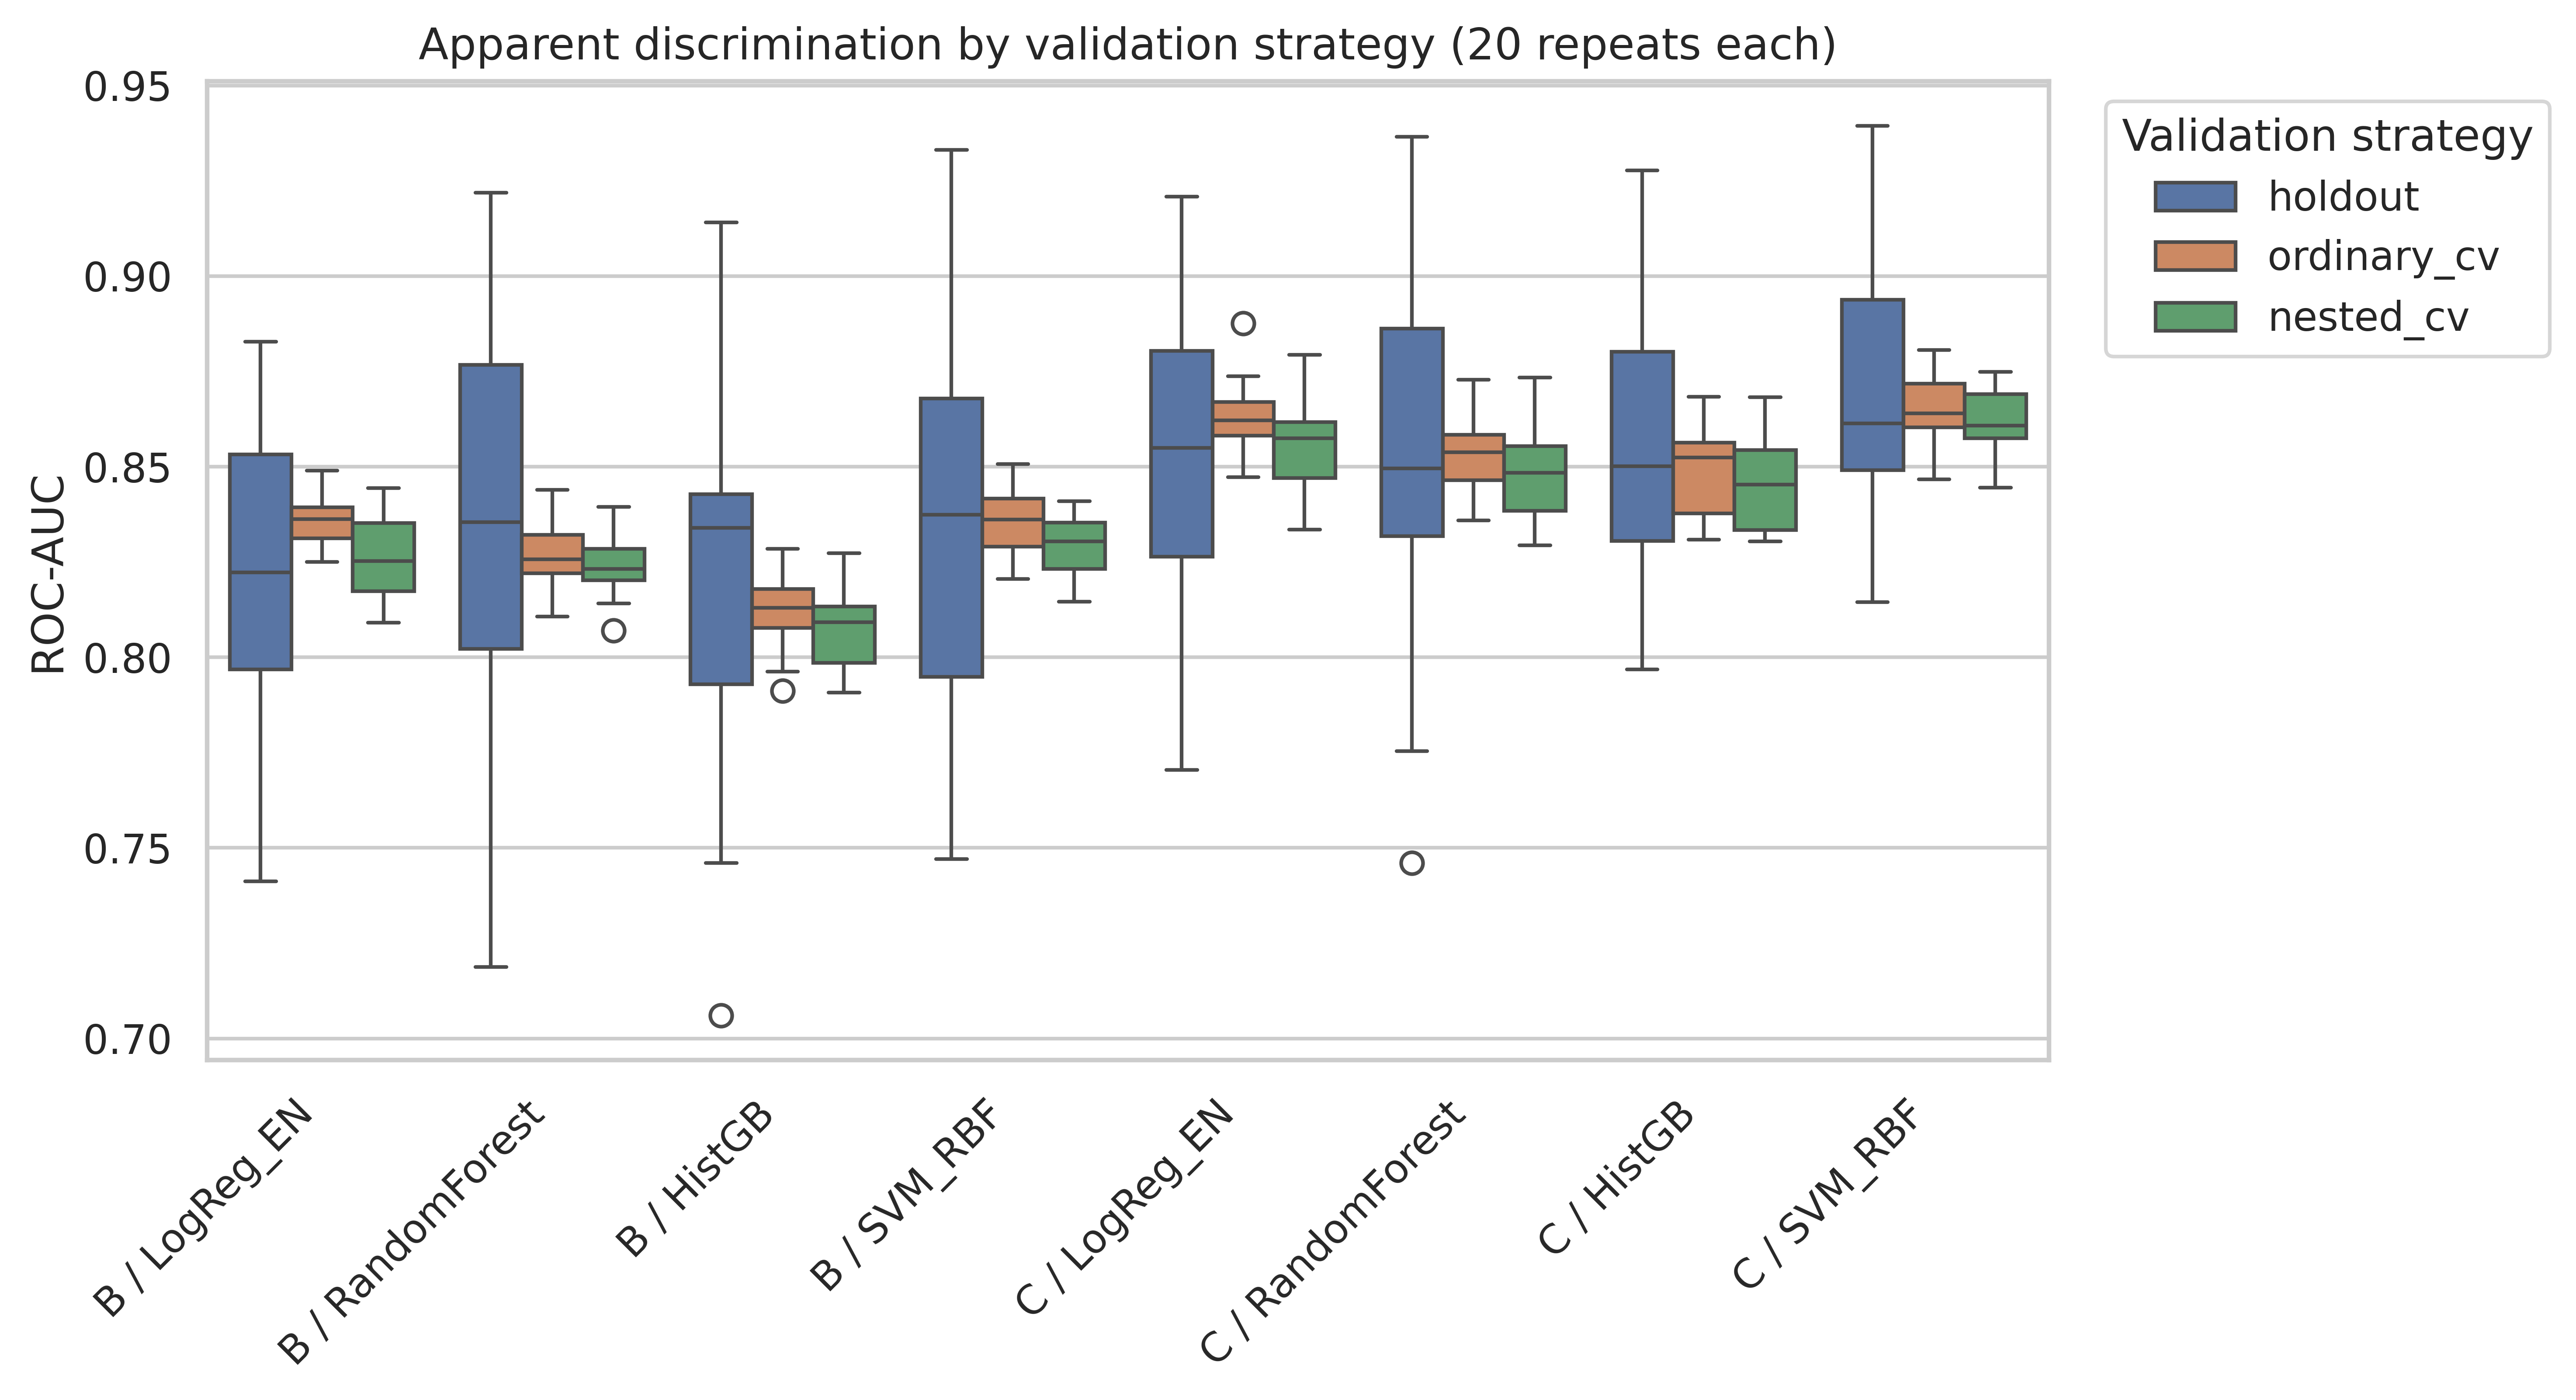

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5.5),dpi=600)
plot_df = exp1_results.copy()
plot_df["group"] = plot_df["tier"] + " / " + plot_df["model"]
order = sorted(plot_df["group"].unique())
sns.boxplot(data=plot_df, x="group", y="auc", hue="strategy", ax=ax,
            hue_order=["holdout", "ordinary_cv", "nested_cv"])
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
ax.set_ylabel("ROC-AUC")
ax.set_xlabel("")
ax.set_title(f"Apparent discrimination by validation strategy ({N_REPEATS_OPTIMISM} repeats each)")
ax.legend(title="Validation strategy", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/fig2_optimism_boxplots.png", dpi=600, bbox_inches="tight")
plt.show()


## 8. Selecting a primary model class for the deep-dive analyses

Calibration, decision-curve analysis, the Tier B vs. Tier C comparison, and conformal prediction are run in
depth for one model class, chosen objectively as the one with the highest mean nested-CV AUC on Tier C
(the richer, harder-to-beat tier). This avoids implicitly cherry-picking whichever model looks best in
whichever analysis. All four model classes remain fully reported in Experiment 1 above.


In [ ]:
nested_only = exp1_results[exp1_results["strategy"] == "nested_cv"]
model_ranking = (nested_only[nested_only["tier"] == "C"]
    .groupby("model")["auc"].mean().sort_values(ascending=False))
print("Mean nested-CV AUC on Tier C, by model class:")
print(model_ranking)

PRIMARY_MODEL = model_ranking.index[0]
print(f"\n=> Primary model selected for deep-dive analyses: {PRIMARY_MODEL}")


Mean nested-CV AUC on Tier C, by model class:
model
SVM_RBF         0.861798
LogReg_EN       0.854608
RandomForest    0.847913
HistGB          0.846201
Name: auc, dtype: float64

=> Primary model selected for deep-dive analyses: SVM_RBF


## 9. Experiment 2: Repeated nested-CV out-of-fold probabilities

Calibration curves and decision-curve analysis both need a predicted probability for every subject that was
produced by a model which never saw that subject during training or hyperparameter tuning. To reduce fold-assignment noise in the resulting curves, we repeat the nested procedure
N_REPEATS_OOF times (different fold shuffles) and average the out-of-fold probability per subject across
repeats. Every individual prediction is still strictly out-of-fold; averaging over repeats only reduces
variance from which particular partition was drawn, and does not introduce leakage.

In [ ]:
def repeated_nested_oof(X, y, features, model_name, repeats, seed0=5000):
    n = len(y)
    oof_matrix = np.full((repeats, n), np.nan)
    for r in range(repeats):
        _, oof = run_nested_cv(X, y, features, model_name, seed=seed0 + r, return_oof=True)
        oof_matrix[r] = oof
    return oof_matrix.mean(axis=0), oof_matrix

oof_path_tpl = f"{RESULTS_DIR}/oof_{{tier}}_{{model}}.npy"
oof_probs = {}
t0 = time.time()
for tier_name, feats in TIERS.items():
    path = oof_path_tpl.format(tier=tier_name, model=PRIMARY_MODEL)
    if os.path.exists(path):
        oof_mean = np.load(path)
        print(f"Loaded cached OOF probabilities for Tier {tier_name}")
    else:
        oof_mean, _ = repeated_nested_oof(df[feats], df["target"].values, feats, PRIMARY_MODEL,
                                           repeats=N_REPEATS_OOF)
        np.save(path, oof_mean)
        print(f"Computed OOF probabilities for Tier {tier_name} in {time.time()-t0:.0f}s")
    oof_probs[tier_name] = oof_mean

y_all = df["target"].values
for tier_name in TIERS:
    print(f"Tier {tier_name}: AUC = {roc_auc_score(y_all, oof_probs[tier_name]):.3f}")

Computed OOF probabilities for Tier B in 22s
Computed OOF probabilities for Tier C in 48s
Tier B: AUC = 0.838
Tier C: AUC = 0.866



## 10. Calibration analysis

Discrimination (AUC) says nothing about whether a predicted probability of 0.7 actually corresponds to a
~70% observed event rate — that is calibration, and it is what a clinician needs if they are going to act on
the number rather than just the rank order. We report:

- **Reliability curves** (observed frequency vs. mean predicted probability, per decile).
- **Brier score** (lower is better; decomposable into calibration + refinement).
- **Calibration slope & intercept** via Cox's logistic recalibration: regress the true outcome on the
  logit of the predicted probability. Slope = 1 and intercept = 0 indicate perfect calibration; slope < 1
  indicates predictions are too extreme (overconfident), slope > 1 too conservative.


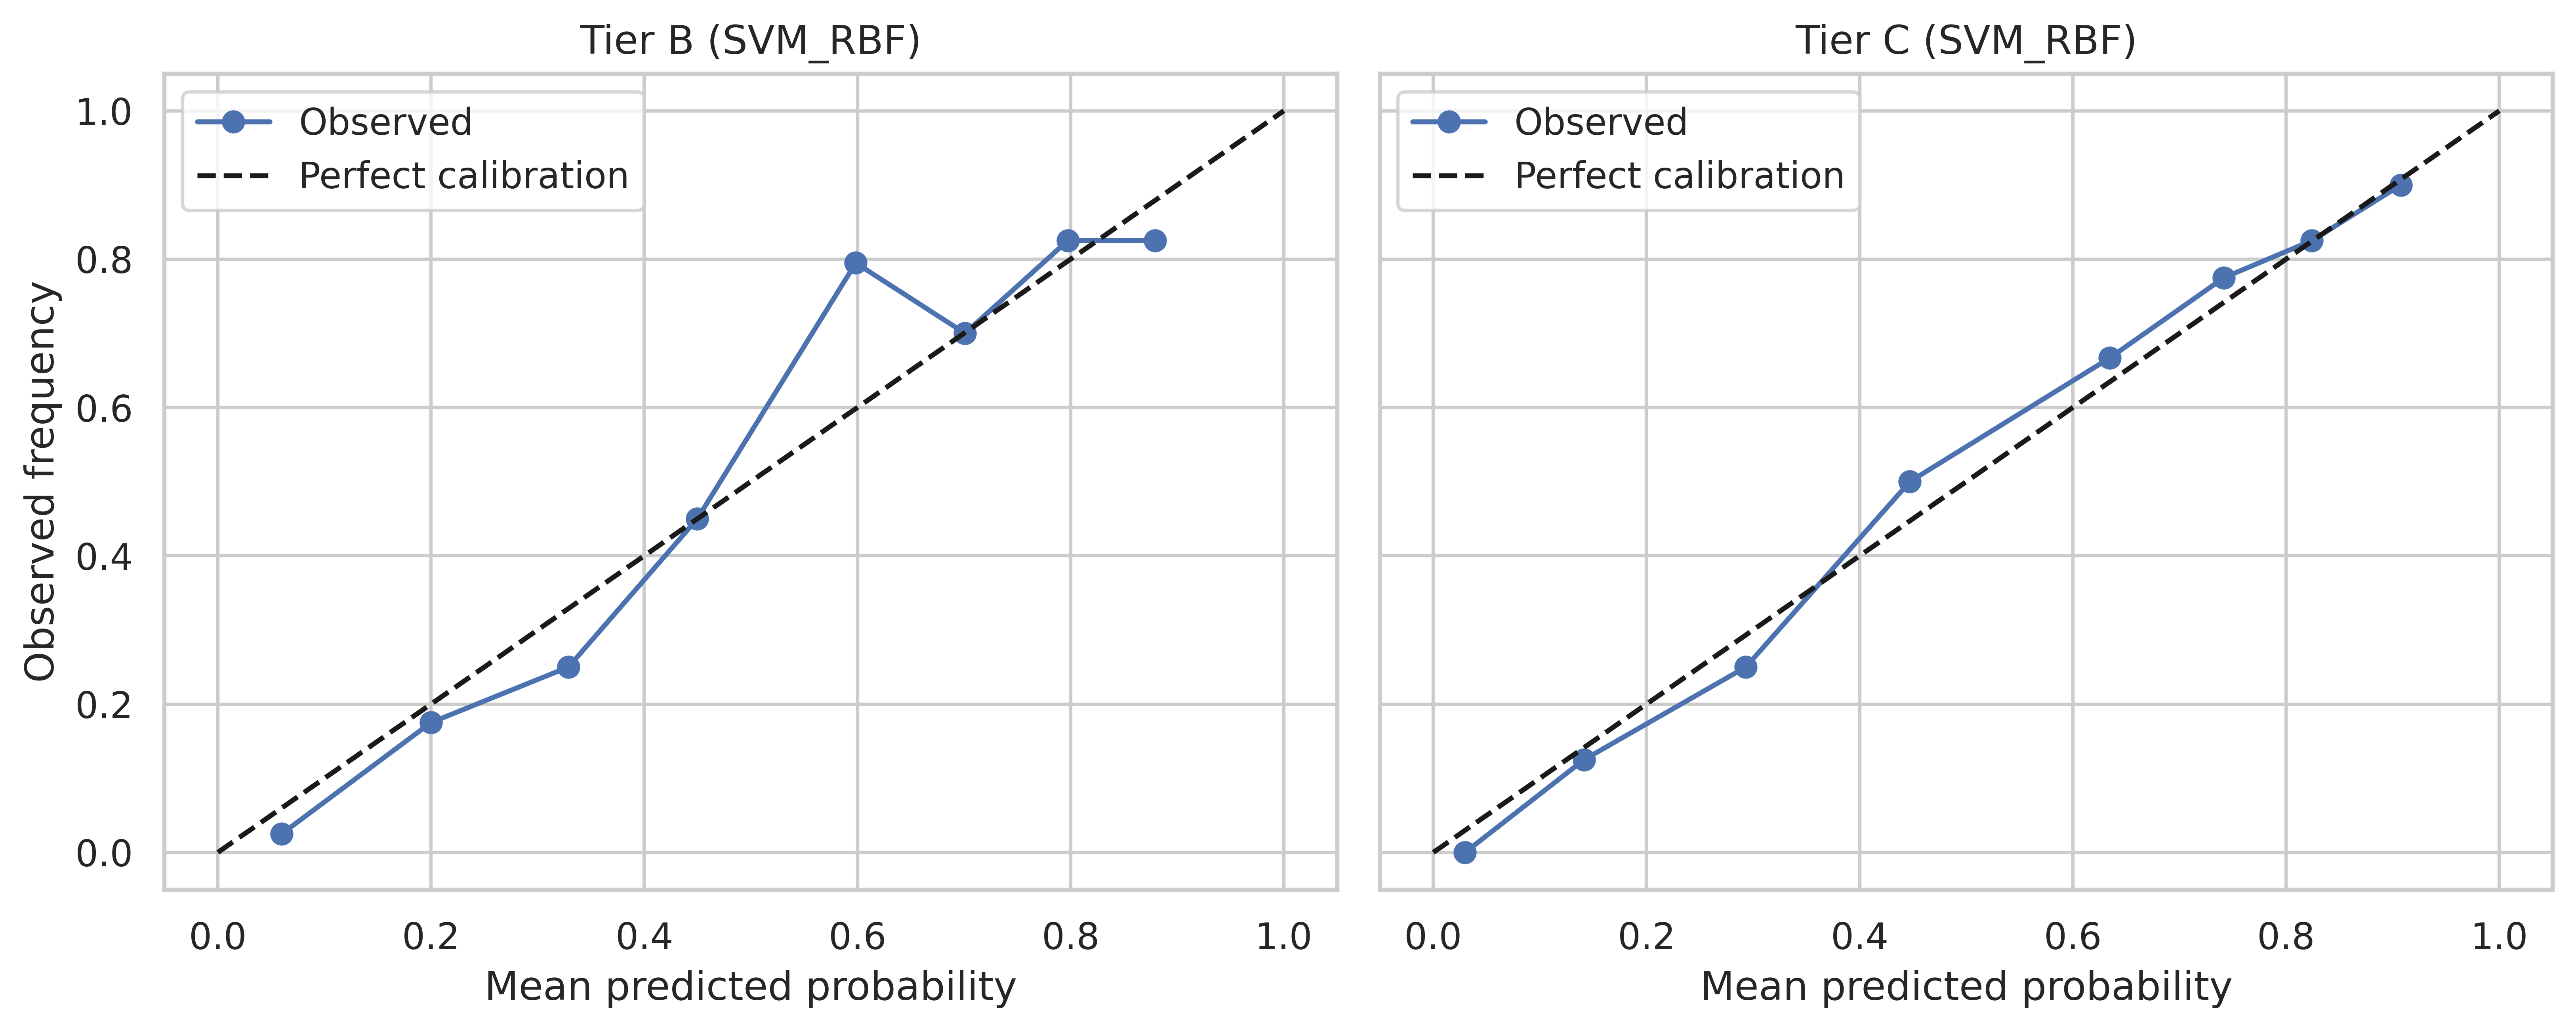

,tier,model,brier,slope,intercept,slope_ci_lo,slope_ci_hi,intercept_ci_lo,intercept_ci_hi
0,B,SVM_RBF,0.161914,1.145004,0.005157,0.885498,1.404511,-0.268838,0.279152
1,C,SVM_RBF,0.146225,1.114628,-0.000691,0.870118,1.359137,-0.291332,0.289949


In [ ]:
def calibration_slope_intercept(y_true, p, eps=1e-6):
    p = np.clip(p, eps, 1 - eps)
    logit_p = np.log(p / (1 - p))
    X = sm.add_constant(logit_p)
    model = sm.Logit(y_true, X).fit(disp=0)
    intercept, slope = model.params
    ci = model.conf_int()
    return dict(slope=slope, intercept=intercept,
                slope_ci_lo=ci[1][0], slope_ci_hi=ci[1][1],
                intercept_ci_lo=ci[0][0], intercept_ci_hi=ci[0][1])

calib_rows = []
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), dpi=600, sharey=True, sharex=True)
for ax, (tier_name, feats) in zip(axes, TIERS.items()):
    p = oof_probs[tier_name]
    frac_pos, mean_pred = calibration_curve(y_all, p, n_bins=8, strategy="quantile")
    ax.plot(mean_pred, frac_pos, "o-", label="Observed")
    ax.plot([0, 1], [0, 1], "k--", label="Perfect calibration")
    ax.set_title(f"Tier {tier_name} ({PRIMARY_MODEL})")
    ax.set_xlabel("Mean predicted probability")
    ax.legend()
    cs = calibration_slope_intercept(y_all, p)
    calib_rows.append(dict(tier=tier_name, model=PRIMARY_MODEL,
                            brier=brier_score_loss(y_all, p), **cs))
axes[0].set_ylabel("Observed frequency")
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/fig3_calibration_curves.png", dpi=600, bbox_inches="tight")
plt.show()

calib_table = pd.DataFrame(calib_rows)
calib_table.to_csv(f"{RESULTS_DIR}/table4_calibration.csv", index=False)
calib_table


## 11. Decision-curve analysis (clinical usability)

Net benefit at threshold *t* trades true positives against false positives weighted by the odds of *t*:

$$NB(t) = \frac{TP}{n} - \frac{FP}{n}\cdot\frac{t}{1-t}$$

We compare the model's net benefit against two reference strategies across a plausible threshold range:
"refer all" (treat/refer every patient) and "refer none" (refer nobody, net benefit fixed at 0). A
model is only clinically usable at a threshold where its net-benefit curve lies above both references. This is a stricter and more decision-relevant bar than "AUC > 0.5" or even "AUC > refer-all-AUC-equivalent".


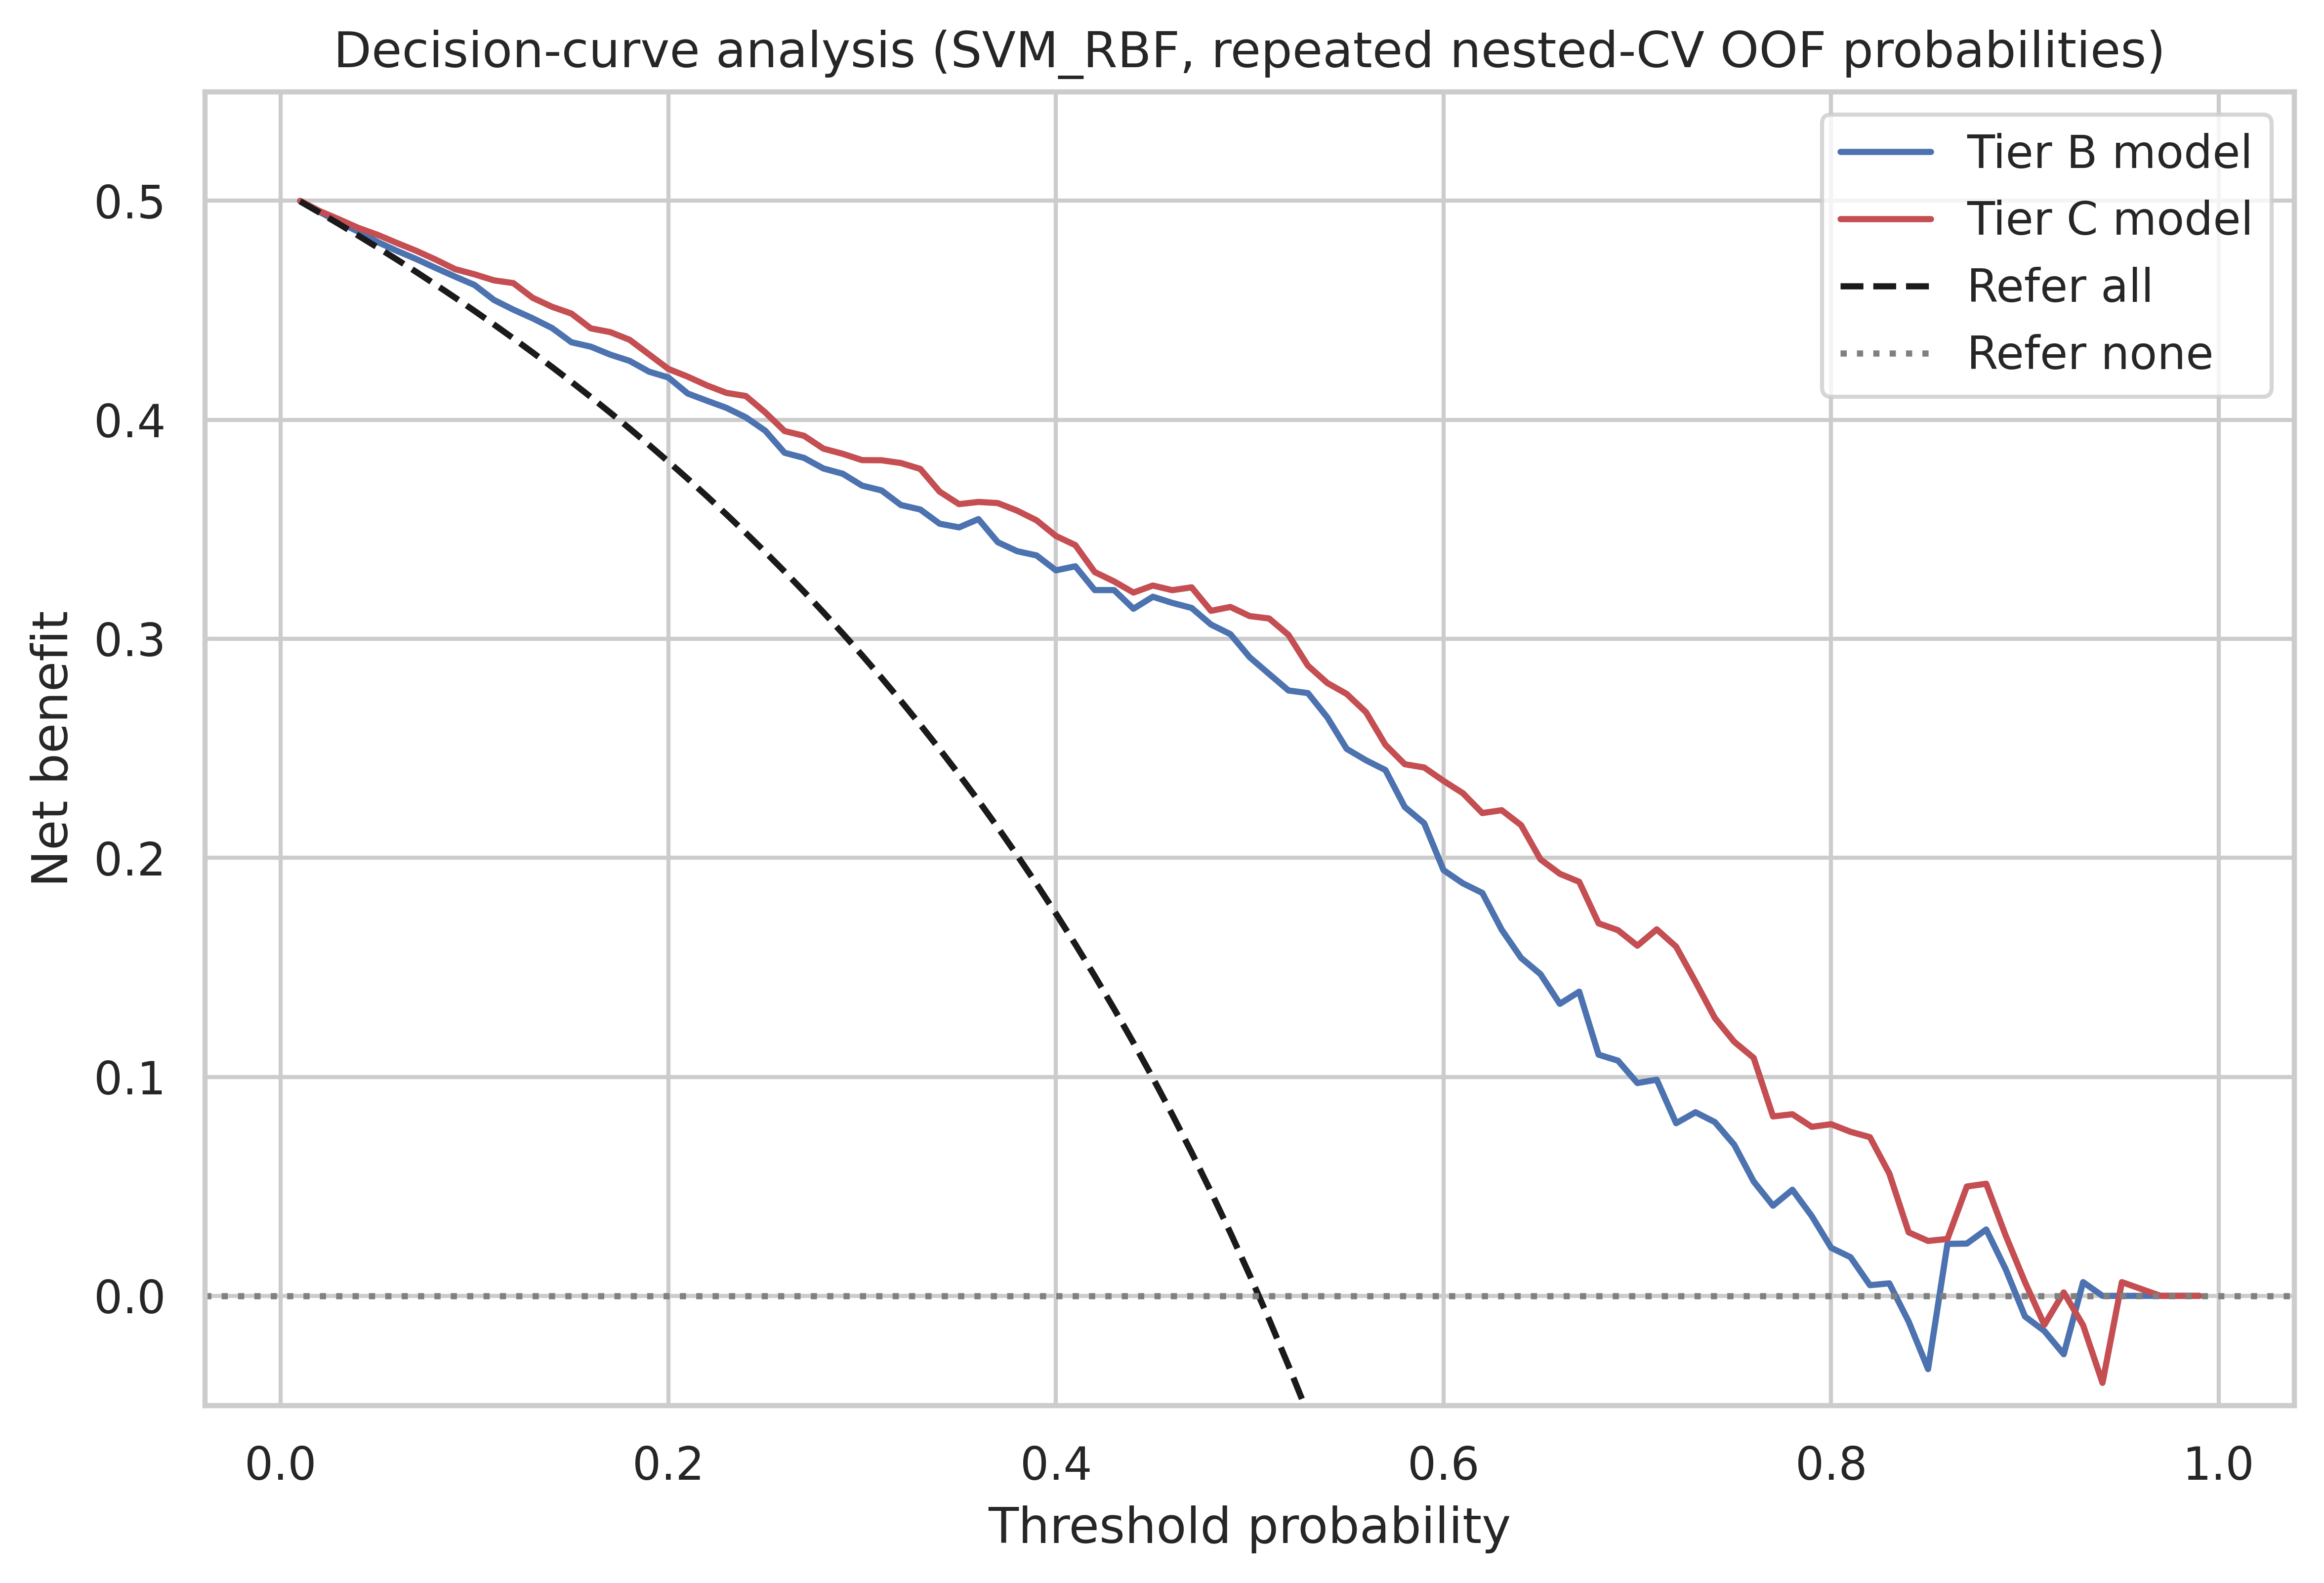

In [ ]:
def decision_curve(y_true, p, thresholds=None):
    if thresholds is None:
        thresholds = np.linspace(0.01, 0.99, 99)
    n = len(y_true)
    prevalence = y_true.mean()
    rows = []
    for t in thresholds:
        pred_pos = p >= t
        tp = np.sum(pred_pos & (y_true == 1))
        fp = np.sum(pred_pos & (y_true == 0))
        nb_model = tp / n - fp / n * (t / (1 - t))
        nb_all = prevalence - (1 - prevalence) * (t / (1 - t))
        rows.append(dict(threshold=t, net_benefit_model=nb_model, net_benefit_treat_all=nb_all))
    return pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(8, 5.5),dpi=600)
dc_tables = {}
colors = {"B": "#4C72B0", "C": "#C44E52"}
for tier_name in TIERS:
    dc = decision_curve(y_all, oof_probs[tier_name])
    dc_tables[tier_name] = dc
    ax.plot(dc["threshold"], dc["net_benefit_model"], label=f"Tier {tier_name} model", color=colors[tier_name])

ax.plot(dc["threshold"], dc["net_benefit_treat_all"], "k--", label="Refer all")
ax.axhline(0, color="gray", linestyle=":", label="Refer none")
ax.set_xlabel("Threshold probability")
ax.set_ylabel("Net benefit")
ax.set_title(f"Decision-curve analysis ({PRIMARY_MODEL}, repeated nested-CV OOF probabilities)")
ax.legend()
ax.set_ylim(-0.05, max(0.5, dc["net_benefit_treat_all"].max() * 1.1))
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/fig4_decision_curve.png", dpi=600, bbox_inches="tight")
plt.show()

for tier_name, dc in dc_tables.items():
    dc.to_csv(f"{RESULTS_DIR}/table5_decision_curve_tier{tier_name}.csv", index=False)

## 12. Experiment 3 — Tier B vs. Tier C incremental value (primary research question)

Both tiers were evaluated on the same subjects with the same model class, so the AUCs are paired/
correlated — we use the DeLong test (via the fast O(n log n) implementation) for a paired significance test,
and a paired bootstrap (resampling subjects, not folds) for a confidence interval on the AUC difference,
using the repeated nested-CV out-of-fold probabilities from Section 9.

In [ ]:
def _compute_midrank(x):
    J = np.argsort(x)
    Z = x[J]
    N = len(x)
    T = np.zeros(N, dtype=float)
    i = 0
    while i < N:
        j = i
        while j < N and Z[j] == Z[i]:
            j += 1
        T[i:j] = 0.5 * (i + j - 1) + 1
        i = j
    T2 = np.empty(N, dtype=float)
    T2[J] = T
    return T2

def _fast_delong(preds_sorted, m):
    n = preds_sorted.shape[1] - m
    k = preds_sorted.shape[0]
    tx = np.empty([k, m]); ty = np.empty([k, n]); tz = np.empty([k, m + n])
    for r in range(k):
        tx[r, :] = _compute_midrank(preds_sorted[r, :m])
        ty[r, :] = _compute_midrank(preds_sorted[r, m:])
        tz[r, :] = _compute_midrank(preds_sorted[r, :])
    aucs = tz[:, :m].sum(axis=1) / m / n - float(m + 1) / (2 * n)
    v01 = (tz[:, :m] - tx[:, :]) / n
    v10 = 1.0 - (tz[:, m:] - ty[:, :]) / m
    sx = np.cov(v01); sy = np.cov(v10)
    delongcov = sx / m + sy / n
    return aucs, delongcov

def delong_paired_test(y_true, p1, p2):
    # Paired DeLong test for two correlated ROC AUCs measured on the same subjects.
    order = np.argsort(-y_true, kind="stable")
    y_true_s, p1_s, p2_s = y_true[order], p1[order], p2[order]
    m = int(np.sum(y_true_s == 1))
    preds = np.vstack([p1_s, p2_s])
    aucs, cov = _fast_delong(preds, m)
    diff = aucs[0] - aucs[1]
    var = cov[0, 0] + cov[1, 1] - 2 * cov[0, 1]
    if var <= 0:
        return dict(auc_1=aucs[0], auc_2=aucs[1], diff=diff, se=np.nan, z=np.nan, p_value=np.nan)
    se = np.sqrt(var)
    z = diff / se
    p_value = 2 * (1 - stats.norm.cdf(abs(z)))
    return dict(auc_1=aucs[0], auc_2=aucs[1], diff=diff, se=se, z=z, p_value=p_value)

def bootstrap_paired_auc_diff(y_true, p1, p2, n_boot, seed=0, alpha=0.05):
    rng = np.random.RandomState(seed)
    idx_pos = np.where(y_true == 1)[0]
    idx_neg = np.where(y_true == 0)[0]
    diffs = np.empty(n_boot)
    for b in range(n_boot):
        bi = np.concatenate([rng.choice(idx_pos, len(idx_pos), replace=True),
                              rng.choice(idx_neg, len(idx_neg), replace=True)])
        try:
            diffs[b] = roc_auc_score(y_true[bi], p1[bi]) - roc_auc_score(y_true[bi], p2[bi])
        except ValueError:
            diffs[b] = np.nan
    diffs = diffs[~np.isnan(diffs)]
    lo, hi = np.percentile(diffs, [100*alpha/2, 100*(1-alpha/2)])
    return dict(mean_diff=diffs.mean(), ci_lo=lo, ci_hi=hi)

delong_res = delong_paired_test(y_all, oof_probs["C"], oof_probs["B"])
boot_res = bootstrap_paired_auc_diff(y_all, oof_probs["C"], oof_probs["B"], n_boot=N_BOOT)

tier_comparison = pd.DataFrame([{
    "model": PRIMARY_MODEL,
    "auc_tier_C": delong_res["auc_1"], "auc_tier_B": delong_res["auc_2"],
    "auc_diff_C_minus_B": delong_res["diff"],
    "delong_p_value": delong_res["p_value"],
    "bootstrap_ci_lo": boot_res["ci_lo"], "bootstrap_ci_hi": boot_res["ci_hi"],
    "brier_tier_C": brier_score_loss(y_all, oof_probs["C"]),
    "brier_tier_B": brier_score_loss(y_all, oof_probs["B"]),
}])
tier_comparison.to_csv(f"{RESULTS_DIR}/table6_tier_comparison.csv", index=False)
tier_comparison


,model,auc_tier_C,auc_tier_B,auc_diff_C_minus_B,delong_p_value,bootstrap_ci_lo,bootstrap_ci_hi,brier_tier_C,brier_tier_B
0,SVM_RBF,0.865555,0.838038,0.027518,0.014687,0.006092,0.04981,0.146225,0.161914


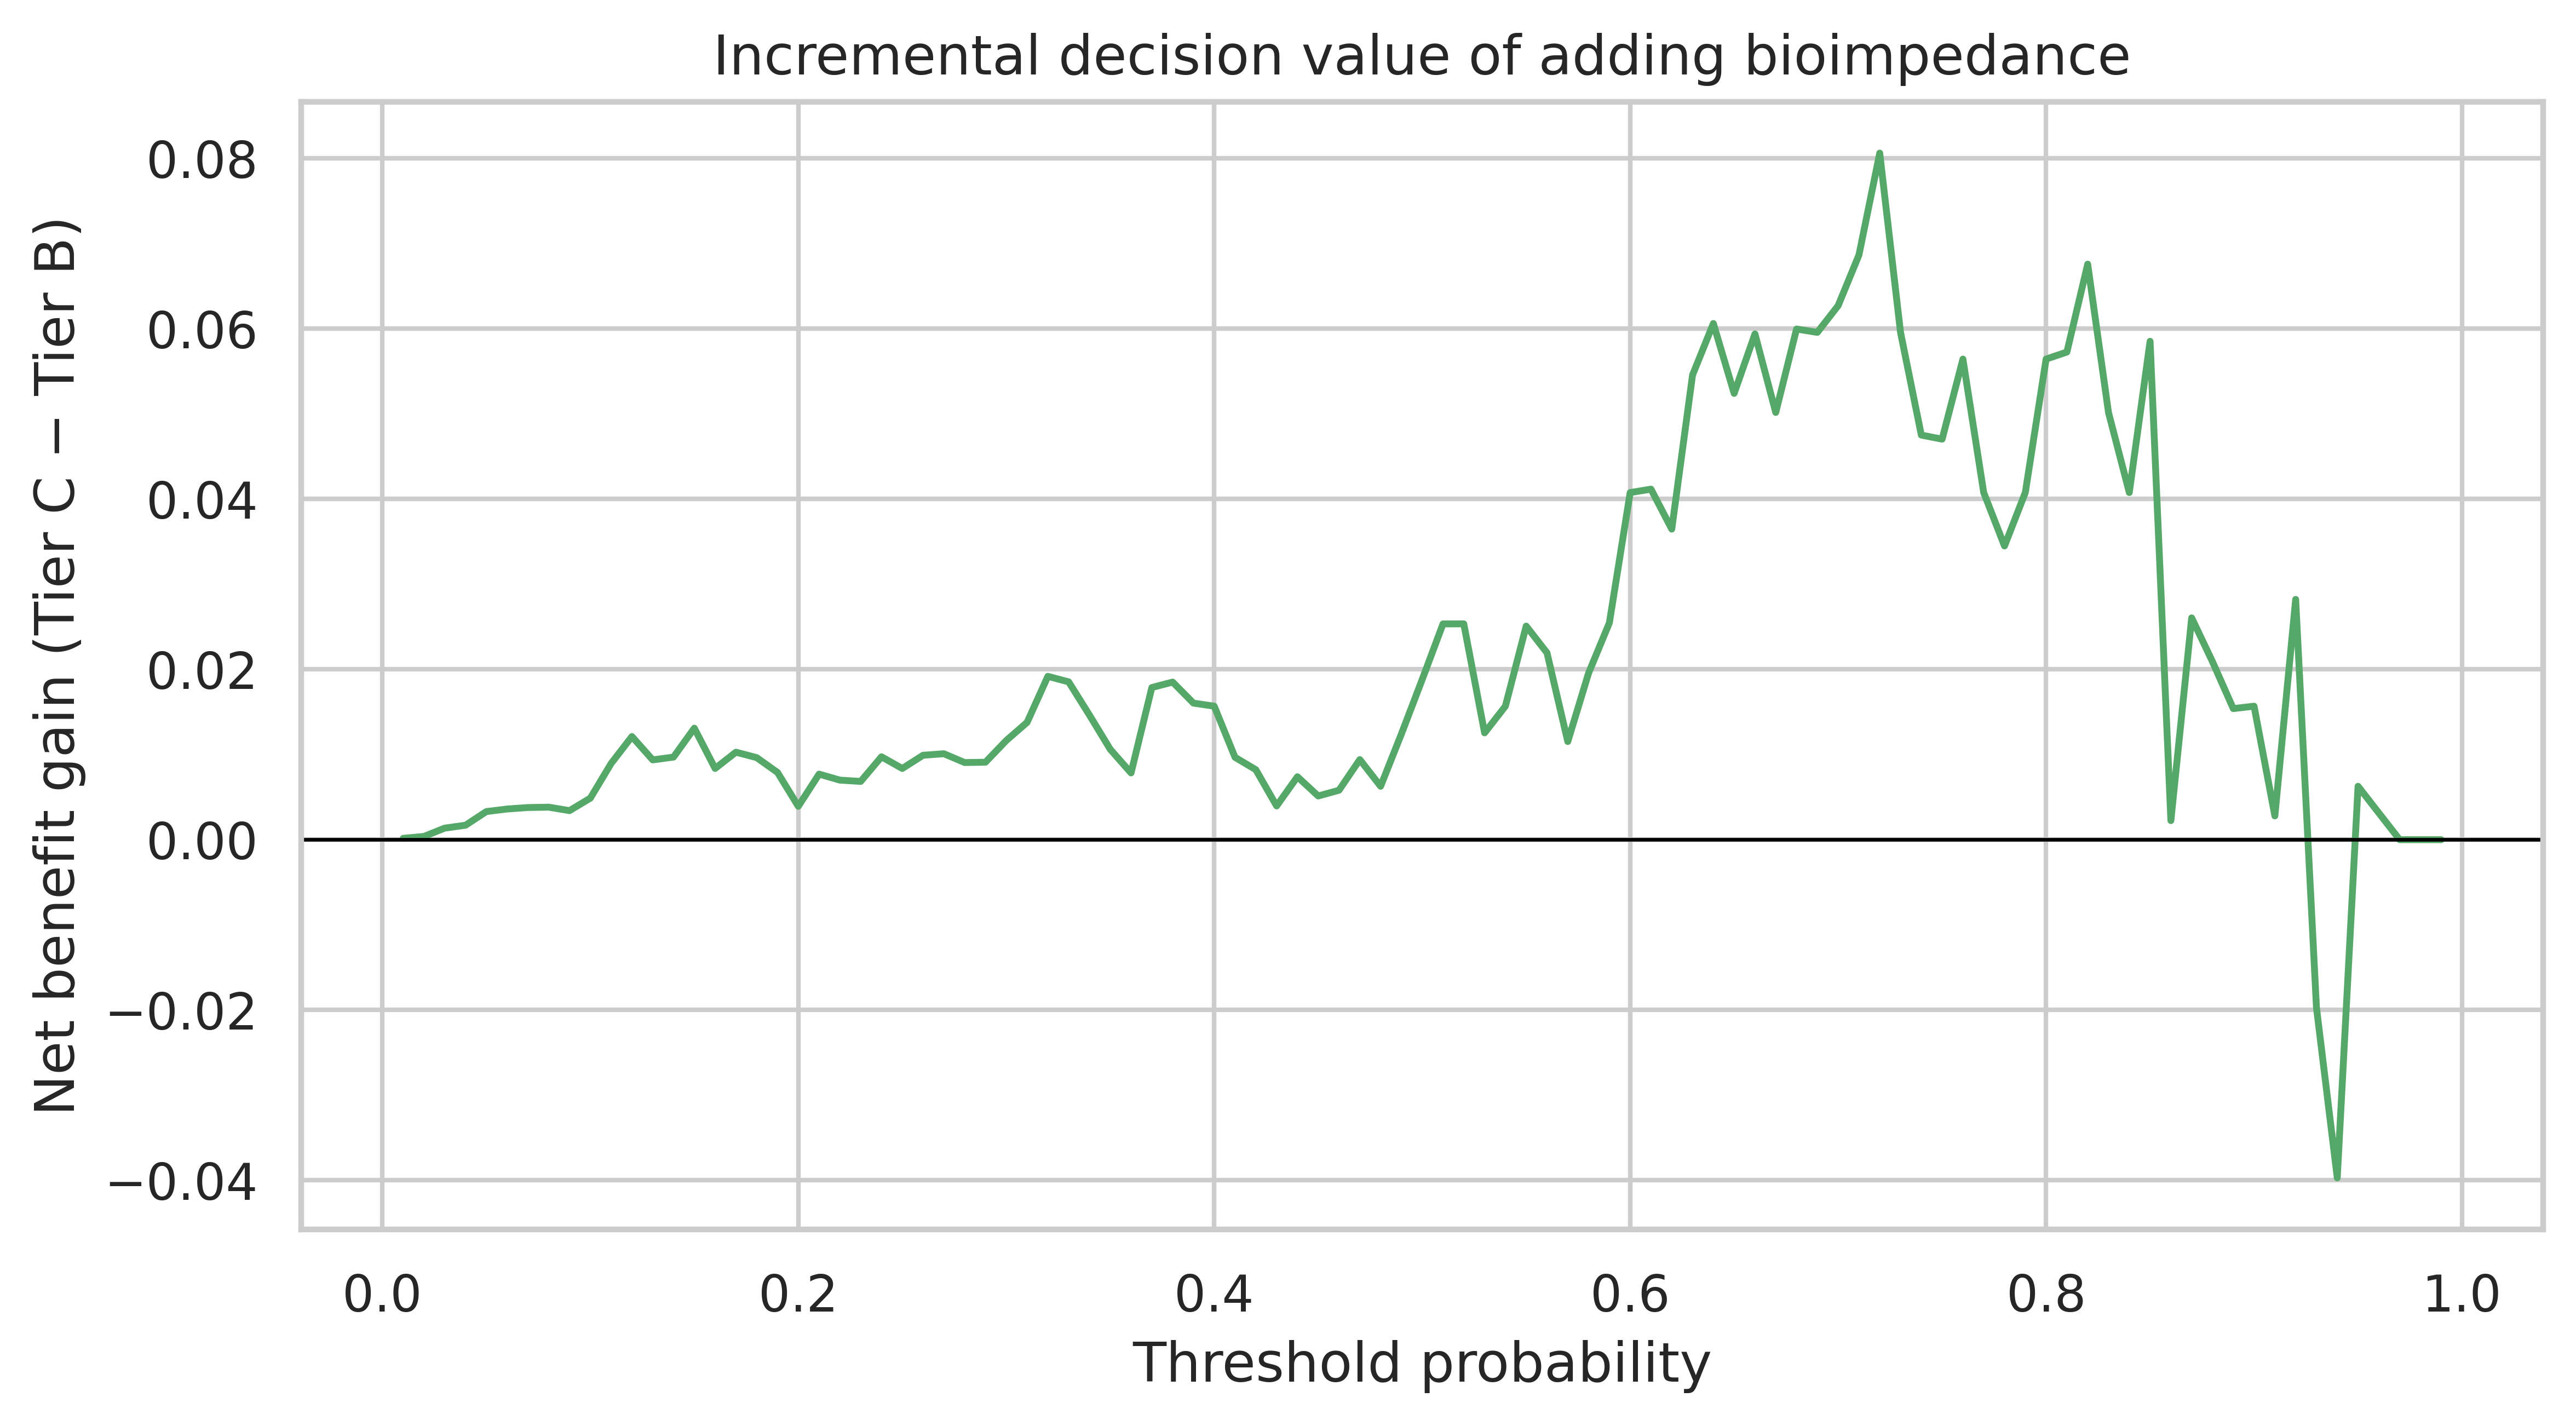

In [ ]:

# Decision-relevant view: does the Tier C net-benefit curve clear the Tier B
# curve, and by how much, across the threshold range?
dc_diff = dc_tables["C"][["threshold"]].copy()
dc_diff["net_benefit_gain_C_over_B"] = (dc_tables["C"]["net_benefit_model"].values
                                         - dc_tables["B"]["net_benefit_model"].values)
fig, ax = plt.subplots(figsize=(8, 4.5),dpi=600)
ax.plot(dc_diff["threshold"], dc_diff["net_benefit_gain_C_over_B"], color="#55A868")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("Threshold probability")
ax.set_ylabel("Net benefit gain (Tier C − Tier B)")
ax.set_title("Incremental decision value of adding bioimpedance")
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/fig5_incremental_net_benefit.png", dpi=600, bbox_inches="tight")
plt.show()
dc_diff.to_csv(f"{RESULTS_DIR}/table7_incremental_net_benefit.csv", index=False)


## 13. Validation-strategy sensitivity of the Tier C − Tier B gain (secondary research question)

This is where the two ideas connect. Using the Experiment 1 results (same model class, same
hyperparameter grid, only the validation strategy and tier vary), we recompute the Tier C − Tier B AUC gap
separately under each of the three validation strategies and ask: would a researcher's conclusion about
"is bioimpedance worth it" have changed depending on which validation strategy they used?

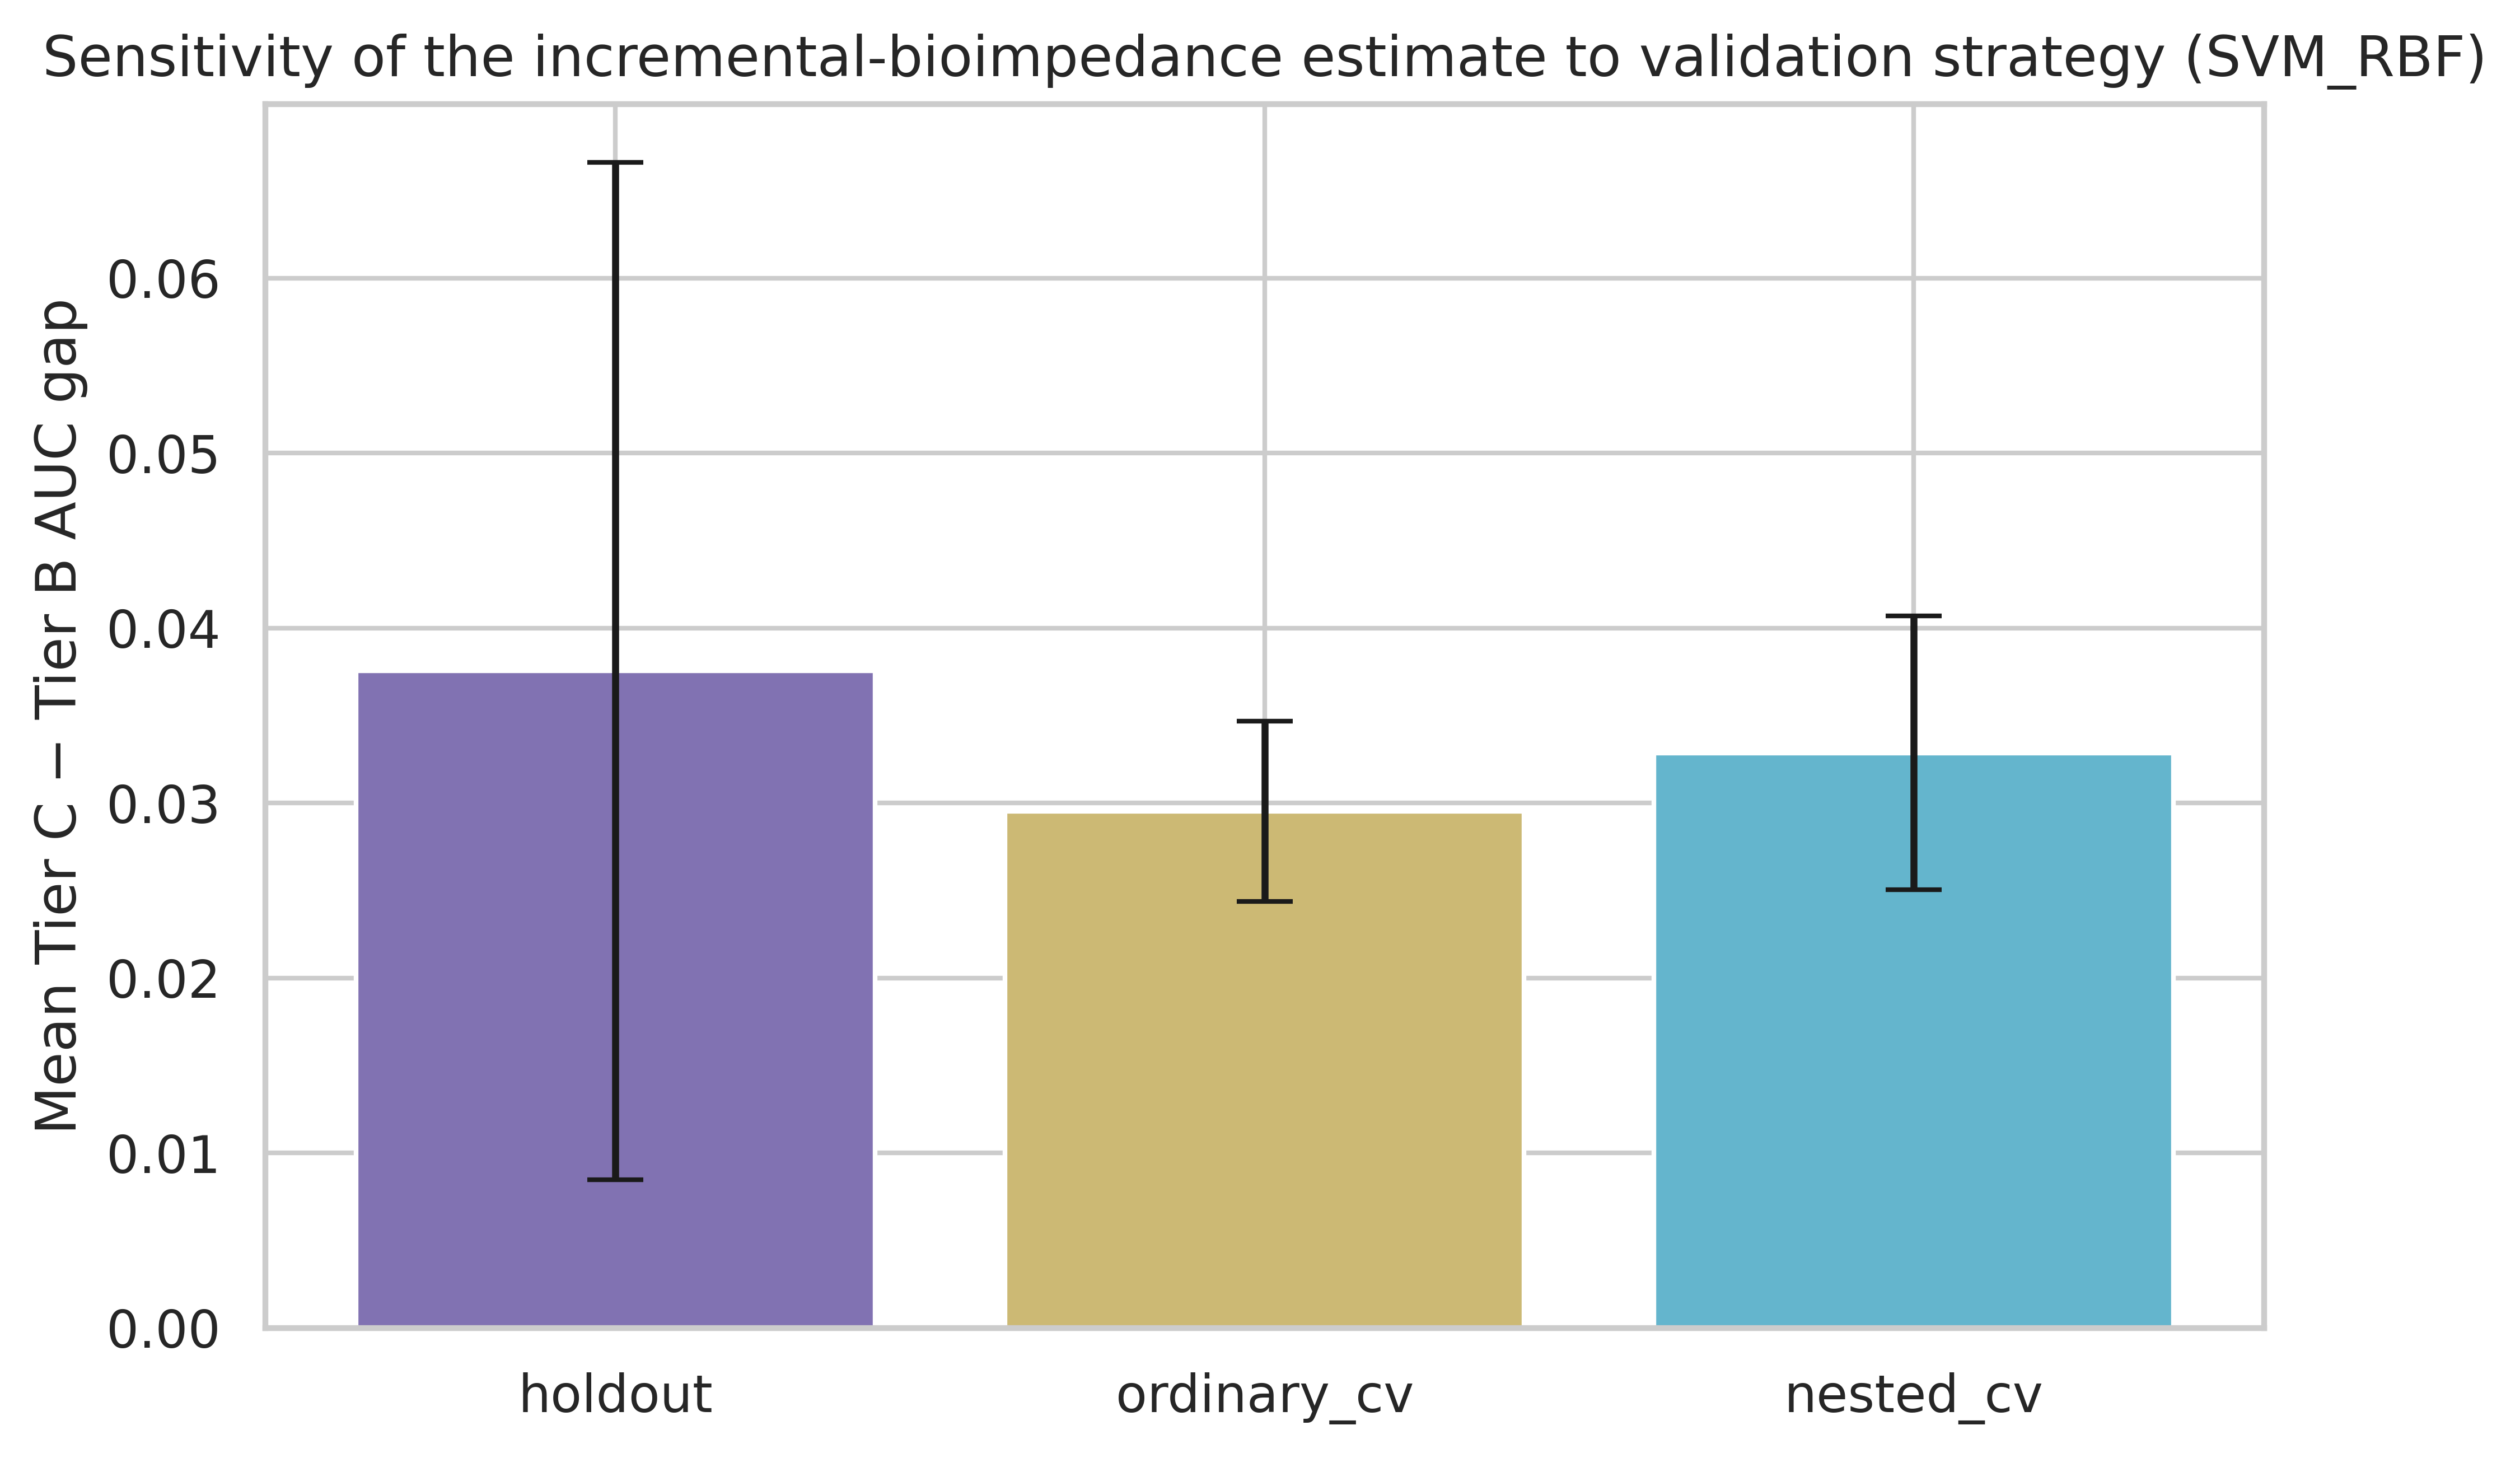

,strategy,mean_gap,std_gap,n_repeats
0,holdout,0.037549,0.029061,20
1,ordinary_cv,0.029523,0.005152,20
2,nested_cv,0.032870,0.007837,20


In [ ]:
gap_rows = []
for strat in ["holdout", "ordinary_cv", "nested_cv"]:
    sub = exp1_results[(exp1_results["strategy"] == strat) & (exp1_results["model"] == PRIMARY_MODEL)]
    piv = sub.pivot_table(index="seed", columns="tier", values="auc")
    gap = piv["C"] - piv["B"]
    gap_rows.append(dict(strategy=strat, mean_gap=gap.mean(), std_gap=gap.std(),
                          n_repeats=len(gap)))
gap_sensitivity = pd.DataFrame(gap_rows)
gap_sensitivity.to_csv(f"{RESULTS_DIR}/table8_validation_sensitivity.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 4.5),dpi=600)
ax.bar(gap_sensitivity["strategy"], gap_sensitivity["mean_gap"],
       yerr=gap_sensitivity["std_gap"], capsize=6, color=["#8172B2", "#CCB974", "#64B5CD"])
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Mean Tier C − Tier B AUC gap")
ax.set_title(f"Sensitivity of the incremental-bioimpedance estimate to validation strategy ({PRIMARY_MODEL})")
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/fig6_validation_sensitivity.png", dpi=600, bbox_inches="tight")
plt.show()
gap_sensitivity



## 14. Experiment 4 — Cross-conformal prediction (safe uncertainty / refer-to-ultrasound band)

A single point probability forces a binary call even when the model is genuinely unsure. Split-conformal
prediction instead returns a prediction set: for a target miscoverage level α (here α = 0.10, targeting
90% coverage), each subject gets a set containing {no disease}, {disease}, or both — a set containing
both classes is the model saying "I cannot separate these two possibilities at the requested confidence
level; this patient should be routed to confirmatory ultrasound rather than given a forced binary answer."

**Leakage-safe cross-conformal implementation:** for every outer fold, the outer-training data is split again
into a *proper-training* set (fits the tuned pipeline) and a *calibration* set (sets the conformal
threshold, using nonconformity score = 1 − p̂(true class)). The outer-test fold is scored against that
threshold and never touches tuning or calibration. This is repeated over N_REPEATS_CONFORMAL outer-loop
repeats and all out-of-fold set predictions are pooled for the coverage/set-size summary. The same repeated
nested discipline used everywhere else in this notebook, extended to set-valued predictions.


In [ ]:
def split_conformal_sets(y_calib, p_calib, p_test_class0, p_test_class1, alpha):
    scores = 1 - p_calib[np.arange(len(y_calib)), y_calib.astype(int)]
    n = len(scores)
    q_level = min(np.ceil((n + 1) * (1 - alpha)) / n, 1.0)
    qhat = np.quantile(scores, q_level, method="higher")
    in_set0 = (1 - p_test_class0) <= qhat
    in_set1 = (1 - p_test_class1) <= qhat
    return in_set0, in_set1

def summarize_conformal_sets(y_true, in_set0, in_set1):
    set_size = in_set0.astype(int) + in_set1.astype(int)
    ambiguous, empty, singleton = (set_size == 2), (set_size == 0), (set_size == 1)
    covered = np.where(y_true == 0, in_set0, in_set1)
    singleton_pred = np.where(in_set0 & ~in_set1, 0, np.where(in_set1 & ~in_set0, 1, -1))
    conf_mask = singleton
    conf_acc = (singleton_pred[conf_mask] == y_true[conf_mask]).mean() if conf_mask.sum() > 0 else np.nan
    return dict(coverage=covered.mean(), pct_ambiguous=ambiguous.mean(), pct_singleton=singleton.mean(),
                pct_empty=empty.mean(), confident_subset_accuracy=conf_acc, n=len(y_true))

def cross_conformal(X, y, features, model_name, alpha, outer_folds, repeats, inner_cv, calib_frac=0.25, seed0=9000):
    est, grid = get_estimator_for(model_name), get_grid_for(model_name)
    all_true, all_in0, all_in1 = [], [], []
    for rep in range(repeats):
        seed = seed0 + rep
        outer = StratifiedKFold(n_splits=outer_folds, shuffle=True, random_state=seed)
        for tr_idx, te_idx in outer.split(X, y):
            Xtr, ytr = X.iloc[tr_idx], y[tr_idx]
            Xte, yte = X.iloc[te_idx], y[te_idx]
            ptr_idx, calib_idx = train_test_split(np.arange(len(ytr)), test_size=calib_frac,
                                                    random_state=seed, stratify=ytr)
            Xptr, yptr = Xtr.iloc[ptr_idx], ytr[ptr_idx]
            Xcal, ycal = Xtr.iloc[calib_idx], ytr[calib_idx]
            pipe = build_pipeline(features, est)
            inner = StratifiedKFold(n_splits=inner_cv, shuffle=True, random_state=seed)
            gs = GridSearchCV(pipe, grid, scoring="roc_auc", cv=inner, n_jobs=-1)
            gs.fit(Xptr, yptr)
            p_cal, p_te = gs.predict_proba(Xcal), gs.predict_proba(Xte)
            in0, in1 = split_conformal_sets(ycal, p_cal, p_te[:, 0], p_te[:, 1], alpha=alpha)
            all_true.append(yte); all_in0.append(in0); all_in1.append(in1)
    y_true = np.concatenate(all_true); in0 = np.concatenate(all_in0); in1 = np.concatenate(all_in1)
    return summarize_conformal_sets(y_true, in0, in1), y_true, in0, in1

conformal_results = {}
t0 = time.time()
for tier_name, feats in TIERS.items():
    summ, yt, in0, in1 = cross_conformal(df[feats], y_all, feats, PRIMARY_MODEL,
                                          alpha=ALPHA_CONFORMAL, outer_folds=OUTER_CV,
                                          repeats=N_REPEATS_CONFORMAL, inner_cv=INNER_CV)
    conformal_results[tier_name] = dict(summary=summ, y_true=yt, in0=in0, in1=in1)
    print(f"Tier {tier_name} conformal summary ({time.time()-t0:.0f}s elapsed):", summ)

conformal_table = pd.DataFrame([{"tier": t, **r["summary"]} for t, r in conformal_results.items()])
conformal_table.to_csv(f"{RESULTS_DIR}/table9_conformal_summary.csv", index=False)
conformal_table


Tier B conformal summary (18s elapsed): {'coverage': np.float64(0.9081504702194357), 'pct_ambiguous': np.float64(0.4536050156739812), 'pct_singleton': np.float64(0.5463949843260189), 'pct_empty': np.float64(0.0), 'confident_subset_accuracy': np.float64(0.831899024670109), 'n': 3190}
Tier C conformal summary (41s elapsed): {'coverage': np.float64(0.9119122257053291), 'pct_ambiguous': np.float64(0.3830721003134796), 'pct_singleton': np.float64(0.6169278996865204), 'pct_empty': np.float64(0.0), 'confident_subset_accuracy': np.float64(0.8572154471544715), 'n': 3190}


,tier,coverage,pct_ambiguous,pct_singleton,pct_empty,confident_subset_accuracy,n
0,B,0.908150,0.453605,0.546395,0.0,0.831899,3190
1,C,0.911912,0.383072,0.616928,0.0,0.857215,3190


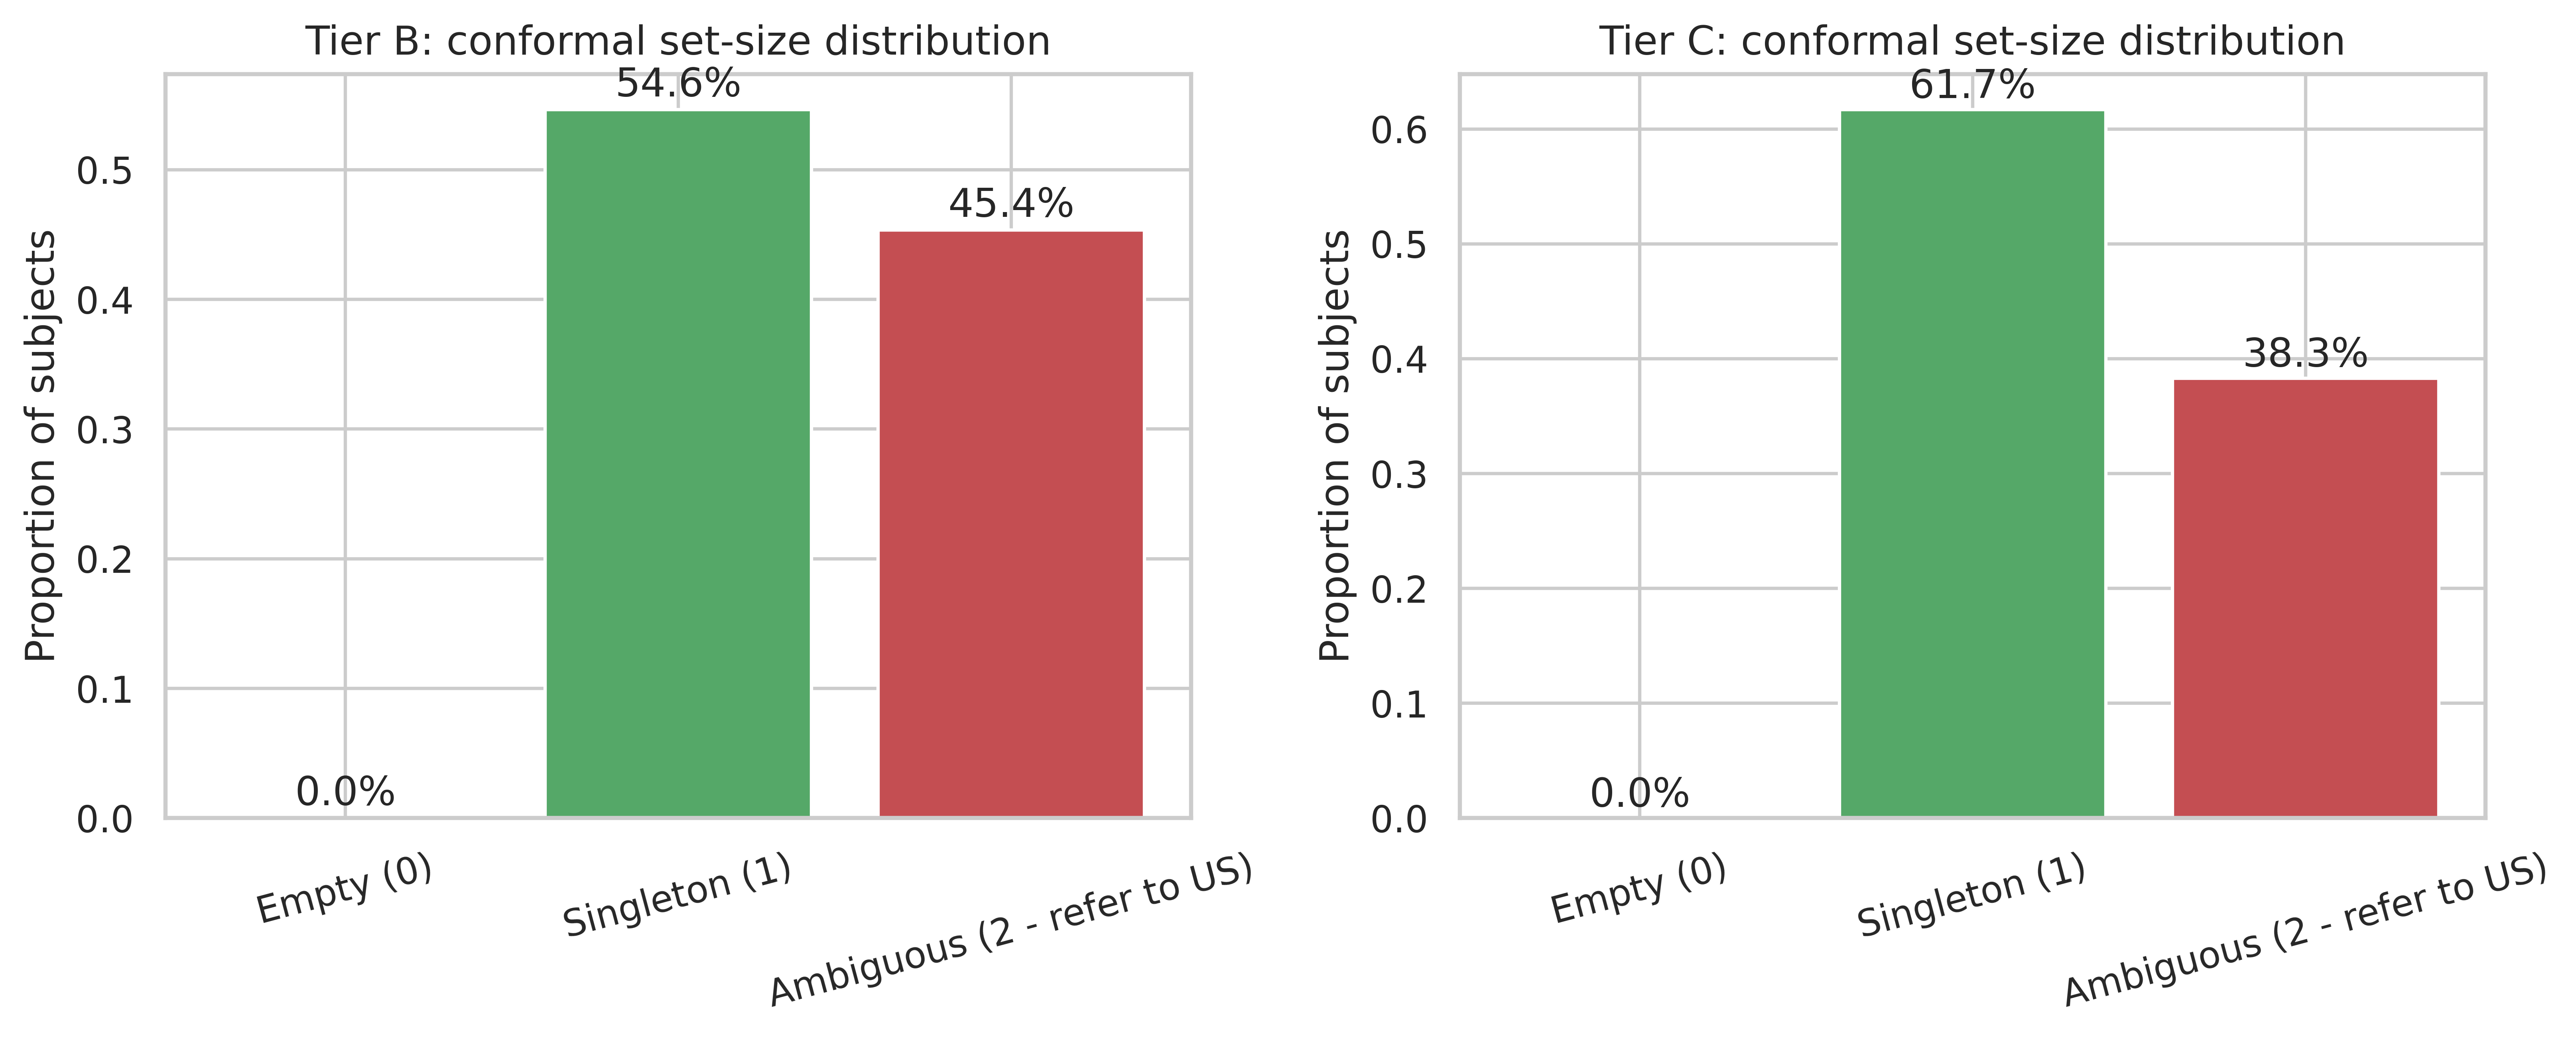

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5),dpi=600)
for ax, (tier_name, res) in zip(axes, conformal_results.items()):
    set_size = res["in0"].astype(int) + res["in1"].astype(int)
    labels = ["Empty (0)", "Singleton (1)", "Ambiguous (2 - refer to US)"]
    counts = [np.mean(set_size == k) for k in [0, 1, 2]]
    ax.bar(labels, counts, color=["#999999", "#55A868", "#C44E52"])
    ax.set_title(f"Tier {tier_name}: conformal set-size distribution")
    ax.set_ylabel("Proportion of subjects")
    ax.tick_params(axis="x", rotation=15)
    for i, c in enumerate(counts):
        ax.text(i, c + 0.01, f"{c:.1%}", ha="center")
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/fig7_conformal_set_sizes.png", dpi=600, bbox_inches="tight")
plt.show()

In [ ]:
# reproducibility
import sklearn, scipy, statsmodels
print("Package versions:")
print(f"  numpy        {np.__version__}")
print(f"  pandas       {pd.__version__}")
print(f"  scikit-learn {sklearn.__version__}")
print(f"  scipy        {scipy.__version__}")
print(f"  statsmodels  {statsmodels.__version__}")
print(f"\nRANDOM_STATE = {RANDOM_STATE}")
#print(f"QUICK_TEST = {QUICK_TEST}")
print(f"N_REPEATS_OPTIMISM={N_REPEATS_OPTIMISM}, N_REPEATS_OOF={N_REPEATS_OOF}, "
      f"N_REPEATS_CONFORMAL={N_REPEATS_CONFORMAL}, N_BOOT={N_BOOT}")
print(f"OUTER_CV={OUTER_CV}, INNER_CV={INNER_CV}, ALPHA_CONFORMAL={ALPHA_CONFORMAL}")


Package versions:
  numpy        2.1.3
  pandas       2.2.3
  scikit-learn 1.6.1
  scipy        1.16.3
  statsmodels  0.14.6

RANDOM_STATE = 42
N_REPEATS_OPTIMISM=20, N_REPEATS_OOF=10, N_REPEATS_CONFORMAL=10, N_BOOT=2000
OUTER_CV=5, INNER_CV=3, ALPHA_CONFORMAL=0.1


## 14. Experiment 5 — Grouped / Modality-Level XAI

### Simple question
**Which part of the extra BIA modality is the Tier C model actually relying on?**

We use two complementary analyses:

1. **Grouped permutation reliance (GPFI-style):** keep the fitted model fixed, jointly shuffle one BIA group in the outer-test data, and measure how much prediction changes.
2. **Leave-One-Group-Out (LOGO):** completely remove one BIA group, retrain the full nested-CV pipeline, and measure how much performance is lost.

These are **semantic/grouped feature analyses**, not TCAV or Concept Bottleneck Models.

**Interpretation rule:** a low grouped-permutation score does not prove that a biological domain is unimportant. It may mean the information is redundant with BMI, weight, laboratory variables, or another BIA group.


In [ ]:
BIA_GROUPS = {
    "BIA_Water": [
        "Total Body Water (TBW)",
        "Extracellular Water (ECW)",
        "Intracellular Water (ICW)",
        "Extracellular Fluid/Total Body Water (ECF/TBW)",
    ],

    "BIA_Adiposity": [
        "Total Body Fat Ratio (TBFR) (%)",
        "Visceral Fat Rating (VFR)",
        "Obesity (%)",
        "Total Fat Content (TFC)",
        "Visceral Fat Area (VFA)",
    ],

    "BIA_Muscle_Lean": [
        "Lean Mass (LM) (%)",
        "Muscle Mass (MM)",
        "Visceral Muscle Area (VMA) (Kg)",
    ],

    "BIA_All": TIER_C_ADDITIONAL_FEATURES,
}

for group_name, group_features in BIA_GROUPS.items():
    print(f"{group_name}: {len(group_features)} feature(s)")


BIA_Water: 4 feature(s)
BIA_Adiposity: 5 feature(s)
BIA_Muscle_Lean: 3 feature(s)
BIA_All: 15 feature(s)


In [ ]:
def grouped_permutation_xai_one_seed(df, features, y, model_name, groups, seed=42, n_permutations=10):

    outer = StratifiedKFold(
        n_splits=OUTER_CV,
        shuffle=True,
        random_state=seed
    )

    n = len(y)
    original_oof = np.full(n, np.nan)
    permuted_oof = {
        group_name: np.full((n_permutations, n), np.nan)
        for group_name in groups
    }

    for fold, (tr_idx, te_idx) in enumerate(
        outer.split(df[features], y), start=1
    ):

        X_train = df.iloc[tr_idx][features].copy()
        X_test  = df.iloc[te_idx][features].copy()
        y_train = y[tr_idx]

        est = get_estimator_for(model_name)
        grid = get_grid_for(model_name)
        pipe = build_pipeline(features, est)

        inner = StratifiedKFold(
            n_splits=INNER_CV,
            shuffle=True,
            random_state=seed
        )

        gs = GridSearchCV(
            pipe,
            grid,
            scoring="roc_auc",
            cv=inner,
            n_jobs=-1
        )

        gs.fit(X_train, y_train)
        p_original = gs.predict_proba(X_test)[:, 1]
        original_oof[te_idx] = p_original
        for group_number, (group_name, group_features) in enumerate(groups.items()):

            available = [f for f in group_features if f in features]

            if len(available) == 0:
                continue

            for perm_id in range(n_permutations):

                X_perm = X_test.copy()

                rng = np.random.RandomState(
                    seed * 100000
                    + fold * 1000
                    + group_number * 100
                    + perm_id
                )

                order = rng.permutation(len(X_perm))

                block = X_perm[available].to_numpy(copy=True)
                X_perm.loc[:, available] = block[order, :]

                p_perm = gs.predict_proba(X_perm)[:, 1]

                permuted_oof[group_name][perm_id, te_idx] = p_perm

    baseline_auc = roc_auc_score(y, original_oof)

    rows = []

    for group_name, perm_matrix in permuted_oof.items():

        for perm_id in range(n_permutations):

            p_perm = perm_matrix[perm_id]

            perturbed_auc = roc_auc_score(y, p_perm)

            probability_change = np.mean(
                np.abs(original_oof - p_perm)
            )

            rows.append({
                "seed": seed,
                "permutation": perm_id + 1,
                "group": group_name,
                "baseline_auc": baseline_auc,
                "perturbed_auc": perturbed_auc,
                "auc_drop": baseline_auc - perturbed_auc,
                "mean_abs_probability_change": probability_change,
            })

    return pd.DataFrame(rows)


In [ ]:
XAI_REPEATS = 5
GROUP_PERMUTATIONS = 10

gpfi_runs = []

for r in range(XAI_REPEATS):

    seed = 12000 + r

    one_run = grouped_permutation_xai_one_seed(
        df=df,
        features=TIER_C_FEATURES,
        y=df["target"].values,
        model_name=PRIMARY_MODEL,
        groups=BIA_GROUPS,
        seed=seed,
        n_permutations=GROUP_PERMUTATIONS,
    )

    gpfi_runs.append(one_run)

    print(f"Grouped permutation repeat {r+1}/{XAI_REPEATS} complete")


gpfi_results = pd.concat(
    gpfi_runs,
    ignore_index=True
)

gpfi_results.to_csv(
    f"{RESULTS_DIR}/experiment5_gpfi_raw.csv",
    index=False
)

gpfi_results.head()


Grouped permutation repeat 1/5 complete
Grouped permutation repeat 2/5 complete
Grouped permutation repeat 3/5 complete
Grouped permutation repeat 4/5 complete
Grouped permutation repeat 5/5 complete


,seed,permutation,group,baseline_auc,perturbed_auc,auc_drop,mean_abs_probability_change
0,12000,1,BIA_Water,0.848848,0.823689,0.025159,0.083398
1,12000,2,BIA_Water,0.848848,0.835246,0.013602,0.088024
2,12000,3,BIA_Water,0.848848,0.841811,0.007037,0.080247
3,12000,4,BIA_Water,0.848848,0.832102,0.016747,0.085777
4,12000,5,BIA_Water,0.848848,0.823139,0.025710,0.085704


             group  gpfi_auc_drop_mean  gpfi_auc_drop_sd  \
0          BIA_All            0.070905          0.014874   
1        BIA_Water            0.022459          0.009150   
2    BIA_Adiposity            0.018735          0.009761   
3  BIA_Muscle_Lean            0.003227          0.002754   

   probability_change_mean  probability_change_sd  
0                 0.139380               0.009536  
1                 0.084973               0.003369  
2                 0.075056               0.005074  
3                 0.029870               0.002714  


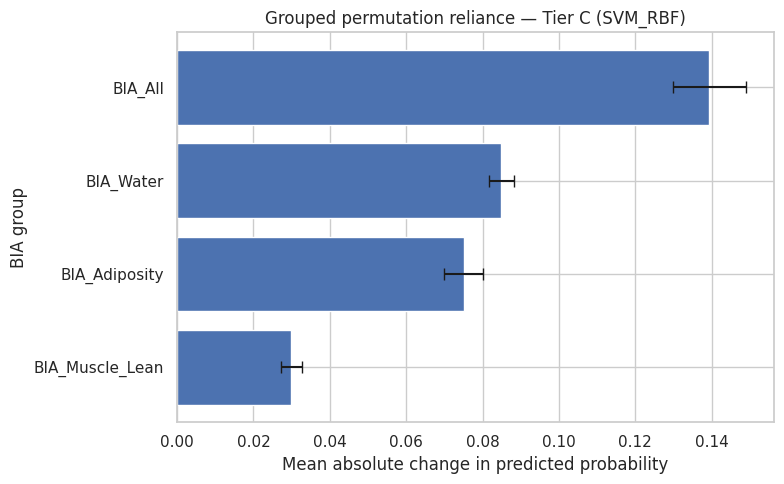

In [ ]:
gpfi_summary = (
    gpfi_results
    .groupby("group")
    .agg(
        gpfi_auc_drop_mean=("auc_drop", "mean"),
        gpfi_auc_drop_sd=("auc_drop", "std"),
        probability_change_mean=("mean_abs_probability_change", "mean"),
        probability_change_sd=("mean_abs_probability_change", "std"),
    )
    .sort_values(
        "probability_change_mean",
        ascending=False
    )
    .reset_index()
)

gpfi_summary.to_csv(
    f"{RESULTS_DIR}/table10_grouped_permutation_xai.csv",
    index=False
)

print(gpfi_summary)


plot_df = gpfi_summary.sort_values(
    "probability_change_mean",
    ascending=True
)

plt.figure(figsize=(8, 5))

plt.barh(
    plot_df["group"],
    plot_df["probability_change_mean"],
    xerr=plot_df["probability_change_sd"],
    capsize=4
)

plt.xlabel("Mean absolute change in predicted probability")
plt.ylabel("BIA group")
plt.title(f"Grouped permutation reliance — Tier C ({PRIMARY_MODEL})")

plt.tight_layout()
plt.savefig(
    f"{FIGURES_DIR}/fig8_grouped_permutation_xai.png",
    dpi=600,
    bbox_inches="tight"
)
plt.show()


### How to read the grouped-permutation result

- Larger **probability change** → the fitted Tier C model relies more strongly on that group.
- Positive **AUC drop** → discrimination worsens after the correct patient-to-group relationship is broken.
- Near-zero importance means **low conditional reliance given all other predictors**, not “biologically unimportant.”
- Correlated predictors can substitute for one another, so permutation importance should be interpreted together with LOGO below.


In [ ]:
def logo_one_seed(
    df,
    y,
    model_name,
    groups,
    seed=42,
):

    _, full_oof = run_nested_cv(
        df[TIER_C_FEATURES],
        y,
        TIER_C_FEATURES,
        model_name,
        seed=seed,
        return_oof=True
    )

    full_auc = roc_auc_score(y, full_oof)

    rows = []

    for group_name, group_features in groups.items():

        reduced_features = [
            f for f in TIER_C_FEATURES
            if f not in group_features
        ]

        _, reduced_oof = run_nested_cv(
            df[reduced_features],
            y,
            reduced_features,
            model_name,
            seed=seed,
            return_oof=True
        )

        reduced_auc = roc_auc_score(y, reduced_oof)

        rows.append({
            "seed": seed,
            "group": group_name,
            "full_auc": full_auc,
            "logo_auc": reduced_auc,
            "logo_auc_drop": full_auc - reduced_auc,
        })

    return pd.DataFrame(rows)


In [ ]:
LOGO_REPEATS = 5

logo_runs = []

for r in range(LOGO_REPEATS):

    seed = 15000 + r

    one_run = logo_one_seed(
        df=df,
        y=df["target"].values,
        model_name=PRIMARY_MODEL,
        groups=BIA_GROUPS,
        seed=seed,
    )

    logo_runs.append(one_run)

    print(f"LOGO repeat {r+1}/{LOGO_REPEATS} complete")


logo_results = pd.concat(
    logo_runs,
    ignore_index=True
)

logo_results.to_csv(
    f"{RESULTS_DIR}/experiment5_logo_raw.csv",
    index=False
)

logo_results.head()


LOGO repeat 1/5 complete
LOGO repeat 2/5 complete
LOGO repeat 3/5 complete
LOGO repeat 4/5 complete
LOGO repeat 5/5 complete


,seed,group,full_auc,logo_auc,logo_auc_drop
0,15000,BIA_Water,0.858951,0.854391,0.004560
1,15000,BIA_Adiposity,0.858951,0.859305,-0.000354
2,15000,BIA_Muscle_Lean,0.858951,0.858126,0.000826
3,15000,BIA_All,0.858951,0.837644,0.021307
4,15001,BIA_Water,0.864887,0.854745,0.010142


In [ ]:
logo_summary = (
    logo_results
    .groupby("group")
    .agg(
        logo_auc_drop_mean=("logo_auc_drop", "mean"),
        logo_auc_drop_sd=("logo_auc_drop", "std"),
        full_auc_mean=("full_auc", "mean"),
        reduced_auc_mean=("logo_auc", "mean"),
    )
    .sort_values(
        "logo_auc_drop_mean",
        ascending=False
    )
    .reset_index()
)

logo_summary.to_csv(
    f"{RESULTS_DIR}/table11_logo_summary.csv",
    index=False
)

logo_summary


,group,logo_auc_drop_mean,logo_auc_drop_sd,full_auc_mean,reduced_auc_mean
0,BIA_All,0.037641,0.011463,0.863606,0.825965
1,BIA_Adiposity,0.008479,0.006581,0.863606,0.855126
2,BIA_Water,0.007438,0.003325,0.863606,0.856168
3,BIA_Muscle_Lean,0.000063,0.003169,0.863606,0.863543


| Pattern | Safer interpretation |
|---|---|
| High permutation + High LOGO | The current model relies on the group, and removing it is difficult to recover from other predictors. |
| High permutation + Low LOGO | The fitted model uses the group, but after retraining the remaining predictors can largely compensate. |
| Low permutation + Low LOGO | Little incremental evidence for this group in the present model/data. |
| Low permutation + High LOGO | A discordant result; inspect correlation, interactions, instability, or permutation artifacts. |


Does the additional BIA modality provide incremental predictive information beyond routine clinical/laboratory variables, and which BIA domain—water, adiposity, or muscle/lean composition—drives that value?



             group  probability_change_mean  probability_change_sd  \
0          BIA_All                 0.139380               0.009536   
1        BIA_Water                 0.084973               0.003369   
2    BIA_Adiposity                 0.075056               0.005074   
3  BIA_Muscle_Lean                 0.029870               0.002714   

   gpfi_auc_drop_mean  gpfi_auc_drop_sd  logo_auc_drop_mean  logo_auc_drop_sd  \
0            0.070905          0.014874            0.037641          0.011463   
1            0.022459          0.009150            0.007438          0.003325   
2            0.018735          0.009761            0.008479          0.006581   
3            0.003227          0.002754            0.000063          0.003169   

   reduced_auc_mean  
0          0.825965  
1          0.856168  
2          0.855126  
3          0.863543  


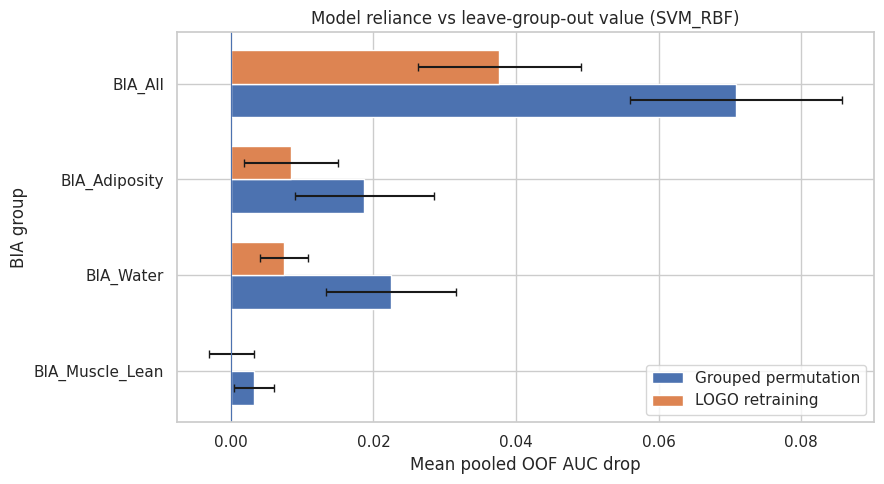

In [ ]:
xai_comparison = gpfi_summary.merge(
    logo_summary[
        [
            "group",
            "logo_auc_drop_mean",
            "logo_auc_drop_sd",
            "reduced_auc_mean",
        ]
    ],
    on="group",
    how="left"
)

xai_comparison = xai_comparison[
    [
        "group",
        "probability_change_mean",
        "probability_change_sd",
        "gpfi_auc_drop_mean",
        "gpfi_auc_drop_sd",
        "logo_auc_drop_mean",
        "logo_auc_drop_sd",
        "reduced_auc_mean",
    ]
]

xai_comparison.to_csv(
    f"{RESULTS_DIR}/table12_gpfi_logo_comparison.csv",
    index=False
)

print(xai_comparison)

plot_df = xai_comparison.sort_values(
    "logo_auc_drop_mean",
    ascending=True
).reset_index(drop=True)

y_pos = np.arange(len(plot_df))
height = 0.35

plt.figure(figsize=(9, 5))

plt.barh(
    y_pos - height/2,
    plot_df["gpfi_auc_drop_mean"],
    height=height,
    xerr=plot_df["gpfi_auc_drop_sd"],
    capsize=3,
    label="Grouped permutation"
)

plt.barh(
    y_pos + height/2,
    plot_df["logo_auc_drop_mean"],
    height=height,
    xerr=plot_df["logo_auc_drop_sd"],
    capsize=3,
    label="LOGO retraining"
)

plt.yticks(y_pos, plot_df["group"])
plt.axvline(0, linewidth=0.8)
plt.xlabel("Mean pooled OOF AUC drop")
plt.ylabel("BIA group")
plt.title(f"Model reliance vs leave-group-out value ({PRIMARY_MODEL})")
plt.legend()

plt.tight_layout()
plt.savefig(
    f"{FIGURES_DIR}/fig9_gpfi_logo_comparison.png",
    dpi=600,
    bbox_inches="tight"
)
plt.show()



## 16. Sex-stratified epidemiology and subgroup calibration audit

Gallstone epidemiology is known to differ by sex, so an acceptable overall calibration curve can potentially
hide subgroup-specific miscalibration. This section **does not train separate male and female prediction models**.
Instead, it audits the same leakage-controlled repeated nested-CV out-of-fold (OOF) predictions already generated
above and asks whether predicted probabilities are equally reliable across the observed `Gender` subgroups.

The analysis includes:

1. **Observed gallstone prevalence by Gender** (epidemiologic context).
2. **Subgroup discrimination and calibration** for Tier B and Tier C: N, prevalence, ROC-AUC, PR-AUC,
   Brier score, calibration intercept, and calibration slope.
3. **Gender-specific reliability curves** using the same OOF probabilities as the main analysis.
4. **Within-Gender Tier B vs Tier C comparison** to examine whether adding BIA features improves probability
   accuracy similarly across subgroups.
5. **Optional Gender-ablation sensitivity analysis** comparing models trained with vs without the `Gender` feature.

**Interpretation:** calibration intercept = 0 and slope = 1 are ideal; lower Brier score is better. A subgroup can
have a good AUC but poor calibration, so subgroup probability reliability should be interpreted separately from
ranking performance. Because subgroup sample sizes may be modest, confidence intervals and estimates should be
reported cautiously.


In [ ]:
GENDER_COL = "Gender"

assert GENDER_COL in df.columns, f"{GENDER_COL} not found in dataframe."
assert "target" in df.columns

gender_levels = sorted(pd.Series(df[GENDER_COL].dropna().unique()).tolist())
print("Observed Gender values:", gender_levels)

GENDER_LABELS = {0: "Male", 1: "Female"}

gender_epi = (
    df.groupby(GENDER_COL)["target"]
      .agg(n="size", gallstone_cases="sum", prevalence="mean")
      .reset_index()
)
gender_epi["subgroup"] = gender_epi[GENDER_COL].map(GENDER_LABELS)
gender_epi = gender_epi[["subgroup", GENDER_COL, "n", "gallstone_cases", "prevalence"]]

gender_epi.to_csv(
    f"{RESULTS_DIR}/table13_gender_epidemiology.csv",
    index=False
)

print("Gallstone prevalence by Gender (target=1 means gallstone present):")
display(gender_epi)

male_prev = gender_epi.loc[gender_epi[GENDER_COL] == 0, "prevalence"].iloc[0]
female_prev = gender_epi.loc[gender_epi[GENDER_COL] == 1, "prevalence"].iloc[0]
direction = "MATCHES" if female_prev > male_prev else "REVERSES"
print(f"This cohort: Male prevalence = {male_prev:.3f}, Female prevalence = {female_prev:.3f} ")

Observed Gender values: [0, 1]
Gallstone prevalence by Gender (target=1 means gallstone present):


,subgroup,Gender,n,gallstone_cases,prevalence
0,Male,0,162,94,0.580247
1,Female,1,157,67,0.426752


This cohort: Male prevalence = 0.580, Female prevalence = 0.427 


In [ ]:

def safe_calibration_slope_intercept(y_true, p, eps=1e-6):
    """Return calibration slope/intercept; NaN if subgroup estimation is unstable."""
    y_true = np.asarray(y_true).astype(int)
    p = np.asarray(p, dtype=float)

    if len(np.unique(y_true)) < 2:
        return dict(
            slope=np.nan, intercept=np.nan,
            slope_ci_lo=np.nan, slope_ci_hi=np.nan,
            intercept_ci_lo=np.nan, intercept_ci_hi=np.nan,
        )

    try:
        return calibration_slope_intercept(y_true, p, eps=eps)
    except Exception as e:
        print(f"Calibration model warning: {e}")
        return dict(
            slope=np.nan, intercept=np.nan,
            slope_ci_lo=np.nan, slope_ci_hi=np.nan,
            intercept_ci_lo=np.nan, intercept_ci_hi=np.nan,
        )


def subgroup_metrics(y_true, p, subgroup_name):
    y_true = np.asarray(y_true).astype(int)
    p = np.asarray(p, dtype=float)

    row = {
        "subgroup": subgroup_name,
        "n": len(y_true),
        "cases": int(y_true.sum()),
        "prevalence": float(y_true.mean()),
        "roc_auc": np.nan,
        "pr_auc": np.nan,
        "brier": brier_score_loss(y_true, p),
    }

    if len(np.unique(y_true)) == 2:
        row["roc_auc"] = roc_auc_score(y_true, p)
        row["pr_auc"] = average_precision_score(y_true, p)

    row.update(safe_calibration_slope_intercept(y_true, p))
    return row


gender_calibration_rows = []

gender_values = df[GENDER_COL].to_numpy()

for tier_name in TIERS:
    p_all = np.asarray(oof_probs[tier_name])

    for g in gender_levels:
        mask = (gender_values == g)
        y_g = y_all[mask]
        p_g = p_all[mask]

        row = subgroup_metrics(y_g, p_g, GENDER_LABELS[g])
        row.update({
            "gender_code": g,
            "tier": tier_name,
            "model": PRIMARY_MODEL,
        })
        gender_calibration_rows.append(row)


gender_calibration_table = pd.DataFrame(gender_calibration_rows)

# Arrange the most important columns first
metric_cols = [
    "tier", "model", "subgroup", "gender_code", "n", "cases", "prevalence",
    "roc_auc", "pr_auc", "brier", "intercept", "intercept_ci_lo", "intercept_ci_hi",
    "slope", "slope_ci_lo", "slope_ci_hi"
]
gender_calibration_table = gender_calibration_table[metric_cols]

gender_calibration_table.to_csv(
    f"{RESULTS_DIR}/table14_gender_subgroup_calibration.csv",
    index=False
)

display(gender_calibration_table)


,tier,model,subgroup,gender_code,n,cases,prevalence,roc_auc,pr_auc,brier,intercept,intercept_ci_lo,intercept_ci_hi,slope,slope_ci_lo,slope_ci_hi
0,B,SVM_RBF,Male,0,162,94,0.580247,0.837453,0.850771,0.155422,-0.058122,-0.472180,0.355936,1.305809,0.886941,1.724678
1,B,SVM_RBF,Female,1,157,67,0.426752,0.827032,0.738079,0.168613,-0.000736,-0.386288,0.384817,1.023786,0.683204,1.364368
2,C,SVM_RBF,Male,0,162,94,0.580247,0.869524,0.881785,0.138644,-0.161777,-0.615941,0.292388,1.309436,0.901528,1.717345
3,C,SVM_RBF,Female,1,157,67,0.426752,0.854561,0.775268,0.154049,0.063779,-0.340840,0.468399,0.996080,0.679496,1.312664


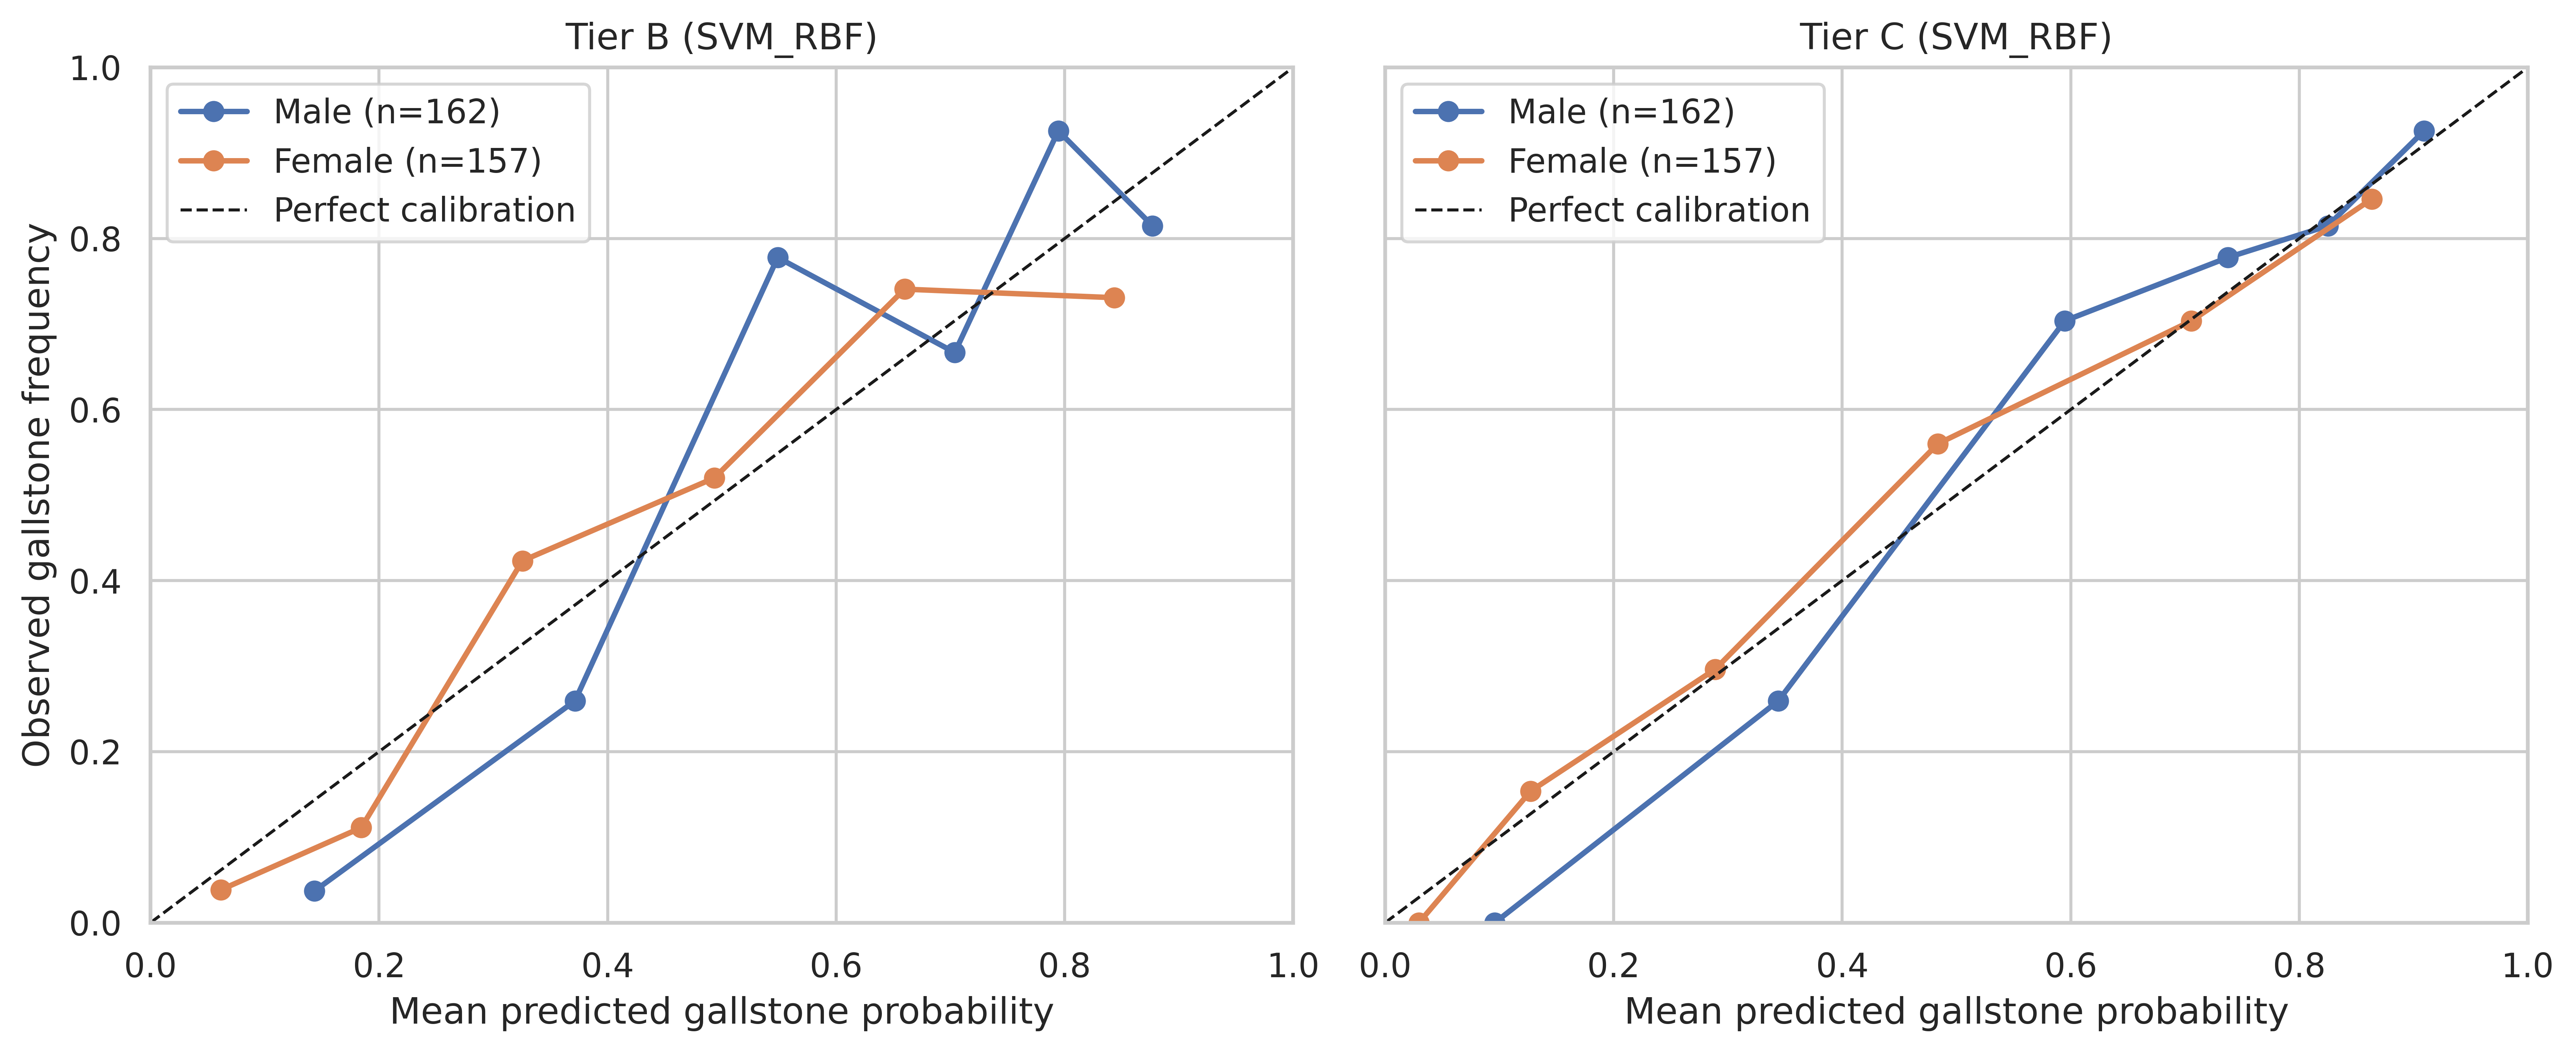

In [ ]:
fig, axes = plt.subplots(
    1, len(TIERS),
    figsize=(6 * len(TIERS), 5),
    dpi=600,
    sharex=True,
    sharey=True,
)

if len(TIERS) == 1:
    axes = [axes]

for ax, tier_name in zip(axes, TIERS.keys()):
    p_all = np.asarray(oof_probs[tier_name])

    for g in gender_levels:
        mask = (gender_values == g)
        y_g = y_all[mask]
        p_g = p_all[mask]


        n_bins = min(6, max(3, len(y_g) // 15))

        if len(y_g) >= n_bins and len(np.unique(y_g)) == 2:
            frac_pos, mean_pred = calibration_curve(
                y_g,
                p_g,
                n_bins=n_bins,
                strategy="quantile"
            )
            ax.plot(
                mean_pred,
                frac_pos,
                marker="o",
                linewidth=1.8,
                label=f"{GENDER_LABELS[g]} (n={len(y_g)})"
            )

    ax.plot([0, 1], [0, 1], "k--", linewidth=1, label="Perfect calibration")
    ax.set_title(f"Tier {tier_name} ({PRIMARY_MODEL})")
    ax.set_xlabel("Mean predicted gallstone probability")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.legend()

axes[0].set_ylabel("Observed gallstone frequency")

plt.tight_layout()
plt.savefig(
    f"{FIGURES_DIR}/fig10_gender_subgroup_calibration.png",
    dpi=600,
    bbox_inches="tight"
)
plt.show()


In [ ]:
assert "B" in oof_probs and "C" in oof_probs, "Tier B and C OOF predictions are required."

gender_tier_rows = []

for g in gender_levels:
    mask = (gender_values == g)
    y_g = y_all[mask]
    p_b = np.asarray(oof_probs["B"])[mask]
    p_c = np.asarray(oof_probs["C"])[mask]

    row = {
        "subgroup": GENDER_LABELS[g],
        "gender_code": g,
        "n": int(mask.sum()),
        "prevalence": float(y_g.mean()),
        "brier_B": brier_score_loss(y_g, p_b),
        "brier_C": brier_score_loss(y_g, p_c),
    }

    row["brier_improvement_B_minus_C"] = row["brier_B"] - row["brier_C"]

    if len(np.unique(y_g)) == 2:
        row["auc_B"] = roc_auc_score(y_g, p_b)
        row["auc_C"] = roc_auc_score(y_g, p_c)
        row["auc_change_C_minus_B"] = row["auc_C"] - row["auc_B"]
        row["pr_auc_B"] = average_precision_score(y_g, p_b)
        row["pr_auc_C"] = average_precision_score(y_g, p_c)
        row["pr_auc_change_C_minus_B"] = row["pr_auc_C"] - row["pr_auc_B"]
    else:
        row.update({
            "auc_B": np.nan, "auc_C": np.nan, "auc_change_C_minus_B": np.nan,
            "pr_auc_B": np.nan, "pr_auc_C": np.nan, "pr_auc_change_C_minus_B": np.nan,
        })

    gender_tier_rows.append(row)


gender_tier_comparison = pd.DataFrame(gender_tier_rows)

gender_tier_comparison.to_csv(
    f"{RESULTS_DIR}/table15_gender_tier_B_vs_C.csv",
    index=False
)

display(gender_tier_comparison)

print("Interpretation:")
print("  • Brier improvement > 0  -> Tier C has better probability accuracy than Tier B.")
print("  • AUC change > 0          -> Tier C has better discrimination than Tier B.")
print("  • Compare the magnitude across Gender subgroups; do not infer an interaction from point estimates alone.")


,subgroup,gender_code,n,prevalence,brier_B,brier_C,brier_improvement_B_minus_C,auc_B,auc_C,auc_change_C_minus_B,pr_auc_B,pr_auc_C,pr_auc_change_C_minus_B
0,Male,0,162,0.580247,0.155422,0.138644,0.016778,0.837453,0.869524,0.032071,0.850771,0.881785,0.031014
1,Female,1,157,0.426752,0.168613,0.154049,0.014564,0.827032,0.854561,0.027529,0.738079,0.775268,0.037189


Interpretation:
  • Brier improvement > 0  -> Tier C has better probability accuracy than Tier B.
  • AUC change > 0          -> Tier C has better discrimination than Tier B.
  • Compare the magnitude across Gender subgroups; do not infer an interaction from point estimates alone.


In [ ]:

def bootstrap_subgroup_tier_difference(y_true, p_b, p_c, n_boot=2000, seed=2026, alpha=0.05):
    """Case/control-stratified bootstrap within one Gender subgroup."""
    y_true = np.asarray(y_true).astype(int)
    p_b = np.asarray(p_b, dtype=float)
    p_c = np.asarray(p_c, dtype=float)

    pos = np.where(y_true == 1)[0]
    neg = np.where(y_true == 0)[0]

    if len(pos) == 0 or len(neg) == 0:
        return {
            "auc_diff_mean": np.nan, "auc_diff_ci_lo": np.nan, "auc_diff_ci_hi": np.nan,
            "brier_improvement_mean": np.nan, "brier_improvement_ci_lo": np.nan, "brier_improvement_ci_hi": np.nan,
        }

    rng = np.random.RandomState(seed)
    auc_diffs = []
    brier_improvements = []

    for _ in range(n_boot):
        idx = np.concatenate([
            rng.choice(pos, size=len(pos), replace=True),
            rng.choice(neg, size=len(neg), replace=True),
        ])

        yb = y_true[idx]
        pb = p_b[idx]
        pc = p_c[idx]

        auc_diffs.append(roc_auc_score(yb, pc) - roc_auc_score(yb, pb))
        brier_improvements.append(
            brier_score_loss(yb, pb) - brier_score_loss(yb, pc)
        )

    auc_diffs = np.asarray(auc_diffs)
    brier_improvements = np.asarray(brier_improvements)
    q = [100 * alpha / 2, 100 * (1 - alpha / 2)]

    return {
        "auc_diff_mean": auc_diffs.mean(),
        "auc_diff_ci_lo": np.percentile(auc_diffs, q[0]),
        "auc_diff_ci_hi": np.percentile(auc_diffs, q[1]),
        "brier_improvement_mean": brier_improvements.mean(),
        "brier_improvement_ci_lo": np.percentile(brier_improvements, q[0]),
        "brier_improvement_ci_hi": np.percentile(brier_improvements, q[1]),
    }


bootstrap_rows = []
for i, g in enumerate(gender_levels):
    mask = (gender_values == g)
    res = bootstrap_subgroup_tier_difference(
        y_all[mask],
        np.asarray(oof_probs["B"])[mask],
        np.asarray(oof_probs["C"])[mask],
        n_boot=N_BOOT,
        seed=21000 + i,
    )
    bootstrap_rows.append({
        "subgroup": GENDER_LABELS[g],
        "gender_code": g,
        "n": int(mask.sum()),
        **res,
    })


gender_tier_bootstrap = pd.DataFrame(bootstrap_rows)
gender_tier_bootstrap.to_csv(
    f"{RESULTS_DIR}/table16_gender_tier_difference_bootstrap.csv",
    index=False
)

display(gender_tier_bootstrap)


,subgroup,gender_code,n,auc_diff_mean,auc_diff_ci_lo,auc_diff_ci_hi,brier_improvement_mean,brier_improvement_ci_lo,brier_improvement_ci_hi
0,Male,0,162,0.032041,-0.005010,0.069309,0.016637,0.002376,0.030836
1,Female,1,157,0.027712,-0.005643,0.061372,0.014707,-0.002184,0.030872


In [ ]:
## Formal test: does the Tier C - Tier B AUC gain differ by sex (interaction)?
def bootstrap_interaction_test(y_all, p_b, p_c, group, label_map, n_boot=2000, seed=31000, alpha=0.05):
    """Paired bootstrap test of a Tier(C-B) x Subgroup interaction (difference-in-differences)."""
    rng = np.random.RandomState(seed)
    groups = np.unique(group)
    assert len(groups) == 2, "Implemented for exactly two subgroups."
    g0, g1 = groups

    def auc_gap(mask):
        yy = y_all[mask]
        return roc_auc_score(yy, p_c[mask]) - roc_auc_score(yy, p_b[mask])

    obs_gap0, obs_gap1 = auc_gap(group == g0), auc_gap(group == g1)
    obs_did = obs_gap1 - obs_gap0

    idx_by_stratum = {(g, cls): np.where((group == g) & (y_all == cls))[0]
                       for g in groups for cls in (0, 1)}

    did_boot = np.empty(n_boot)
    for b in range(n_boot):
        gap = {}
        for g in groups:
            bi = np.concatenate([rng.choice(idx_by_stratum[(g, cls)], size=len(idx_by_stratum[(g, cls)]), replace=True)
                                  for cls in (0, 1)])
            yy = y_all[bi]
            gap[g] = roc_auc_score(yy, p_c[bi]) - roc_auc_score(yy, p_b[bi])
        did_boot[b] = gap[g1] - gap[g0]

    ci_lo, ci_hi = np.percentile(did_boot, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    p_value = min(2 * min((did_boot >= 0).mean(), (did_boot <= 0).mean()), 1.0)

    return dict(group_0=label_map[g0], group_1=label_map[g1],
                auc_gap_group0=obs_gap0, auc_gap_group1=obs_gap1,
                did_C_minus_B=obs_did, did_ci_lo=ci_lo, did_ci_hi=ci_hi,
                did_bootstrap_p=p_value)

interaction_result = bootstrap_interaction_test(
    y_all=y_all, p_b=np.asarray(oof_probs["B"]), p_c=np.asarray(oof_probs["C"]),
    group=gender_values, label_map=GENDER_LABELS, n_boot=N_BOOT, seed=31000,
)

interaction_df = pd.DataFrame([interaction_result])
interaction_df.to_csv(f"{RESULTS_DIR}/table17_sex_tier_interaction_test.csv", index=False)
display(interaction_df)

print(f"DID = (AUC_C-AUC_B | {interaction_result['group_1']}) - (AUC_C-AUC_B | {interaction_result['group_0']}) "
      f"= {interaction_result['did_C_minus_B']:.4f} "
      f"[{interaction_result['did_ci_lo']:.4f}, {interaction_result['did_ci_hi']:.4f}], "
      f"bootstrap p = {interaction_result['did_bootstrap_p']:.3f}")
print("A CI excluding 0 / p<0.05 supports a genuine sex-differential BIA benefit;")
print("if it includes 0, the separate per-subgroup CIs above are NOT evidence of a real interaction.")

,group_0,group_1,auc_gap_group0,auc_gap_group1,did_C_minus_B,did_ci_lo,did_ci_hi,did_bootstrap_p
0,Male,Female,0.032071,0.027529,-0.004542,-0.05423,0.044961,0.855


DID = (AUC_C-AUC_B | Female) - (AUC_C-AUC_B | Male) = -0.0045 [-0.0542, 0.0450], bootstrap p = 0.855
A CI excluding 0 / p<0.05 supports a genuine sex-differential BIA benefit;
if it includes 0, the separate per-subgroup CIs above are NOT evidence of a real interaction.


In [ ]:
## Multiplicity: label the single confirmatory test vs. the family of secondary/exploratory tests
from statsmodels.stats.multitest import multipletests

exploratory_pvalues = pd.DataFrame(
    [{"family": "Exp1_optimism_ordinary_vs_nested", "test": f"{row.tier}/{row.model} Wilcoxon",
      "p_value": row.wilcoxon_p} for row in optimism_tests.itertuples()]
    + [{"family": "Sex_stratified_secondary", "test": "Tier(C-B) x Sex interaction (DID bootstrap)",
        "p_value": interaction_result["did_bootstrap_p"]}]
)

reject, p_adj, _, _ = multipletests(exploratory_pvalues["p_value"].values, alpha=0.05, method="fdr_bh")
exploratory_pvalues["p_value_bh_adjusted"] = p_adj
exploratory_pvalues["reject_at_fdr_0.05"] = reject
exploratory_pvalues.to_csv(f"{RESULTS_DIR}/table18_multiplicity_adjusted_pvalues.csv", index=False)
display(exploratory_pvalues)

print(f"The single pre-specified confirmatory test is the Tier C vs Tier B DeLong test "
      f"(p = {delong_res['p_value']:.4f}), interpreted without correction.")

,family,test,p_value,p_value_bh_adjusted,reject_at_fdr_0.05
0,Exp1_optimism_ordinary_vs_nested,B/HistGB Wilcoxon,0.000261,0.000470,True
1,Exp1_optimism_ordinary_vs_nested,B/LogReg_EN Wilcoxon,0.000036,0.000082,True
2,Exp1_optimism_ordinary_vs_nested,B/RandomForest Wilcoxon,0.000708,0.000796,True
3,Exp1_optimism_ordinary_vs_nested,B/SVM_RBF Wilcoxon,0.000002,0.000009,True
4,Exp1_optimism_ordinary_vs_nested,C/HistGB Wilcoxon,0.000483,0.000620,True
5,Exp1_optimism_ordinary_vs_nested,C/LogReg_EN Wilcoxon,0.000002,0.000009,True
6,Exp1_optimism_ordinary_vs_nested,C/RandomForest Wilcoxon,0.000019,0.000057,True
7,Exp1_optimism_ordinary_vs_nested,C/SVM_RBF Wilcoxon,0.000395,0.000592,True
8,Sex_stratified_secondary,Tier(C-B) x Sex interaction (DID bootstrap),0.855000,0.855000,False


The single pre-specified confirmatory test is the Tier C vs Tier B DeLong test (p = 0.0147), interpreted without correction.


In [ ]:
## Sensitivity analysis: is the Tier C-B result driven by the implausible Obesity (%) value?
SENSITIVITY_OOF_REPEATS = 10
df_sens = df.copy()
outlier_col = "Obesity (%)"
outlier_mask = df_sens[outlier_col] > 100
print(f"Flagged {outlier_mask.sum()} row(s) with {outlier_col} > 100:")
print(df_sens.loc[outlier_mask, [outlier_col]])

cap_value = df_sens.loc[~outlier_mask, outlier_col].quantile(0.99)
df_sens.loc[outlier_mask, outlier_col] = cap_value
print(f"\nWinsorized flagged value(s) to the 99th percentile of the remaining distribution ({cap_value:.2f}).")

oof_probs_sens = {}
for tier_name, feats in TIERS.items():
    oof_mean_sens, _ = repeated_nested_oof(
        df_sens[feats], df_sens["target"].values, feats, PRIMARY_MODEL,
        repeats=SENSITIVITY_OOF_REPEATS, seed0=7000,
    )
    oof_probs_sens[tier_name] = oof_mean_sens
    print(f"[Sensitivity] Tier {tier_name} AUC = {roc_auc_score(y_all, oof_mean_sens):.4f}")

delong_res_sens = delong_paired_test(y_all, oof_probs_sens["C"], oof_probs_sens["B"])
boot_res_sens = bootstrap_paired_auc_diff(y_all, oof_probs_sens["C"], oof_probs_sens["B"], n_boot=N_BOOT, seed=1)

sensitivity_comparison = pd.DataFrame([
    {"analysis": "Main (outlier retained)", "auc_tier_C": delong_res["auc_1"], "auc_tier_B": delong_res["auc_2"],
     "auc_diff_C_minus_B": delong_res["diff"], "delong_p_value": delong_res["p_value"],
     "bootstrap_ci_lo": boot_res["ci_lo"], "bootstrap_ci_hi": boot_res["ci_hi"]},
    {"analysis": "Sensitivity (outlier winsorized)", "auc_tier_C": delong_res_sens["auc_1"], "auc_tier_B": delong_res_sens["auc_2"],
     "auc_diff_C_minus_B": delong_res_sens["diff"], "delong_p_value": delong_res_sens["p_value"],
     "bootstrap_ci_lo": boot_res_sens["ci_lo"], "bootstrap_ci_hi": boot_res_sens["ci_hi"]},
])
sensitivity_comparison.to_csv(f"{RESULTS_DIR}/table19_outlier_sensitivity.csv", index=False)
display(sensitivity_comparison)

print("\nIf the Tier C-B gap, its sign, and significance are materially unchanged after winsorizing the")
print(f"single implausible {outlier_col} value, the main result is not driven by that data-entry artifact.")

Flagged 3 row(s) with Obesity (%) > 100:
     Obesity (%)
23         125.6
209        106.3
239       1954.0

Winsorized flagged value(s) to the 99th percentile of the remaining distribution (85.40).
[Sensitivity] Tier B AUC = 0.8372
[Sensitivity] Tier C AUC = 0.8674


,analysis,auc_tier_C,auc_tier_B,auc_diff_C_minus_B,delong_p_value,bootstrap_ci_lo,bootstrap_ci_hi
0,Main (outlier retained),0.865555,0.838038,0.027518,0.014687,0.006092,0.049810
1,Sensitivity (outlier winsorized),0.867403,0.837212,0.030191,0.004937,0.009313,0.051852



If the Tier C-B gap, its sign, and significance are materially unchanged after winsorizing the
single implausible Obesity (%) value, the main result is not driven by that data-entry artifact.


Tier B feature-importance repeat 1/5 complete
Tier B feature-importance repeat 2/5 complete
Tier B feature-importance repeat 3/5 complete
Tier B feature-importance repeat 4/5 complete
Tier B feature-importance repeat 5/5 complete


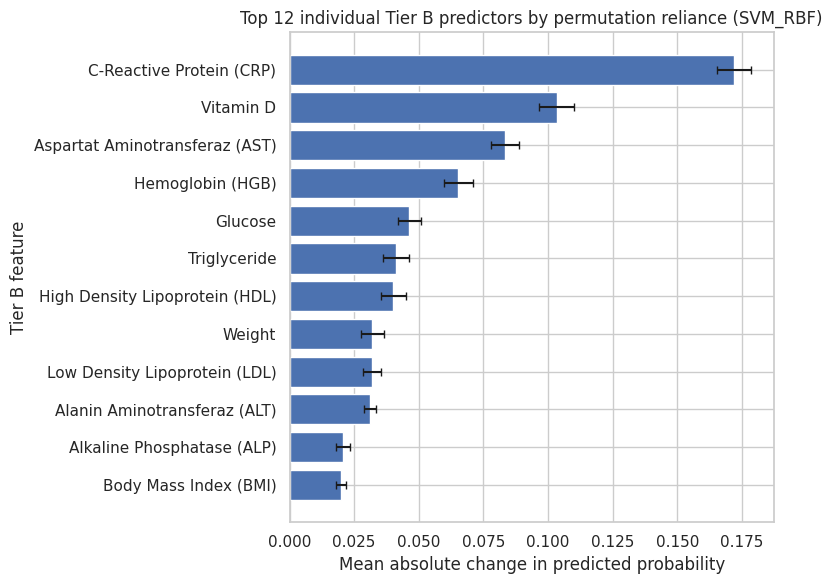

,tier_B_feature,auc_drop_mean,auc_drop_sd,probability_change_mean,probability_change_sd
0,C-Reactive Protein (CRP),0.174709,0.020784,0.172028,0.006483
1,Vitamin D,0.049897,0.015604,0.103306,0.006944
2,Aspartat Aminotransferaz (AST),0.032884,0.011903,0.083431,0.005405
3,Hemoglobin (HGB),0.020416,0.008090,0.065369,0.005648
4,Glucose,0.010047,0.007426,0.046304,0.004450
5,Triglyceride,0.003172,0.006294,0.041201,0.005100
6,High Density Lipoprotein (HDL),0.008348,0.004707,0.040118,0.004911
7,Weight,0.001957,0.004369,0.032084,0.004370
8,Low Density Lipoprotein (LDL),0.002912,0.004609,0.031880,0.003381
9,Alanin Aminotransferaz (ALT),0.002613,0.004732,0.031155,0.002256


In [ ]:
## Tier B individual-feature importance (out-of-fold permutation)
TIER_B_SINGLETON_GROUPS = {f: [f] for f in TIER_B_FEATURES}

tierB_fi_runs = []
for r in range(XAI_REPEATS):
    seed = 13000 + r
    one_run = grouped_permutation_xai_one_seed(
        df=df, features=TIER_B_FEATURES, y=df["target"].values,
        model_name=PRIMARY_MODEL, groups=TIER_B_SINGLETON_GROUPS,
        seed=seed, n_permutations=GROUP_PERMUTATIONS,
    )
    tierB_fi_runs.append(one_run)
    print(f"Tier B feature-importance repeat {r+1}/{XAI_REPEATS} complete")

tierB_fi_results = pd.concat(tierB_fi_runs, ignore_index=True)
tierB_fi_results.to_csv(f"{RESULTS_DIR}/experiment5b_tierB_feature_importance_raw.csv", index=False)

tierB_fi_summary = (
    tierB_fi_results.groupby("group")
    .agg(auc_drop_mean=("auc_drop", "mean"), auc_drop_sd=("auc_drop", "std"),
         probability_change_mean=("mean_abs_probability_change", "mean"),
         probability_change_sd=("mean_abs_probability_change", "std"))
    .sort_values("probability_change_mean", ascending=False)
    .reset_index().rename(columns={"group": "tier_B_feature"})
)
tierB_fi_summary.to_csv(f"{RESULTS_DIR}/table20_tierB_feature_importance.csv", index=False)

top_n = 12
plot_df = tierB_fi_summary.head(top_n).sort_values("probability_change_mean", ascending=True)
plt.figure(figsize=(8, 6))
plt.barh(plot_df["tier_B_feature"], plot_df["probability_change_mean"],
         xerr=plot_df["probability_change_sd"], capsize=3)
plt.xlabel("Mean absolute change in predicted probability")
plt.ylabel("Tier B feature")
plt.title(f"Top {top_n} individual Tier B predictors by permutation reliance ({PRIMARY_MODEL})")
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/fig11_tierB_individual_feature_importance.png", dpi=600, bbox_inches="tight")
plt.show()

display(tierB_fi_summary)